# Forecasting WAV service risk in New York City

**Research question:** How accurately can the borough-level share of completed WAV-requested HVFHV trips whose vehicle arrives more than 10 minutes after the requested pickup time be forecast one four-hour period ahead, using only information available beforehand?

# 1. Project setup and configuration

In [1]:
import os
import sys
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from tempfile import TemporaryDirectory

In [2]:
PROJECT_ROOT = Path.cwd().resolve()

print(f"Project root: {PROJECT_ROOT}")
print(f"Python executable: {sys.executable}")

Project root: /Users/lavenderle/project-1-individual-LavenderLe7
Python executable: /Users/lavenderle/project-1-individual-LavenderLe7/.venv/bin/python


In [3]:
RANDOM_SEED = 42
TIMEZONE = "America/New_York"

ANALYSIS_YEAR = 2025
ANALYSIS_MONTHS = tuple(range(4, 13))

ANALYSIS_START = "2025-04-01 00:00:00"
TRAIN_END_EXCLUSIVE = "2025-09-01 00:00:00"
VALIDATION_END_EXCLUSIVE = "2025-11-01 00:00:00"
ANALYSIS_END_EXCLUSIVE = "2026-01-01 00:00:00"
TEST_END_EXCLUSIVE = ANALYSIS_END_EXCLUSIVE

PERIOD_HOURS = 4
FORECAST_HORIZON_PERIODS = 1
DATA_MATURITY_BUFFER_PERIODS = 1
HISTORICAL_FEATURE_LAG_PERIODS = (
    FORECAST_HORIZON_PERIODS + DATA_MATURITY_BUFFER_PERIODS
)
LATE_THRESHOLD_MINUTES = 10
WAV_REQUEST_FLAG_VALUE = "Y"

NYC_BOROUGHS = (
    "Bronx",
    "Brooklyn",
    "Manhattan",
    "Queens",
    "Staten Island",
)

HRRR_DATASET_ID = "noaa-hrrr-forecast-48-hour"
HRRR_INIT_START_UTC = "2025-03-31 00:00:00"
HRRR_INIT_END_UTC = "2026-01-01 06:00:00"
HRRR_INIT_FREQUENCY = "6h"
HRRR_FORECAST_AVAILABILITY_BUFFER_HOURS = 3
HRRR_DOWNLOAD_MAX_WORKERS = 8
HRRR_VARIABLES = (
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation_surface",
    "categorical_rain_surface",
    "wind_u_10m",
    "wind_v_10m",
    "wind_gust_surface",
)


In [4]:
# Input data roots
RAW_DATA_ROOT = PROJECT_ROOT / "data" / "raw"
REFERENCE_DATA_ROOT = PROJECT_ROOT / "data" / "reference"

# Pipeline-generated data roots
STANDARDIZED_DATA_ROOT = PROJECT_ROOT / "data" / "standardized"
CURATED_DATA_ROOT = PROJECT_ROOT / "data" / "curated"

In [5]:
# Processed data outputs
STANDARDIZED_WAV_REQUEST_ROOT = STANDARDIZED_DATA_ROOT / "wav_requests"
STANDARDIZED_WAV_REQUEST_PATHS = tuple(
    STANDARDIZED_WAV_REQUEST_ROOT
    / f"wav_requests_{ANALYSIS_YEAR}-{month:02d}.parquet"
    for month in ANALYSIS_MONTHS
)
HRRR_OUTPUT_ROOT = STANDARDIZED_DATA_ROOT / "hrrr_forecasts"
HRRR_COMBINED_PATH = (
    HRRR_OUTPUT_ROOT
    / "hrrr_borough_forecasts_standardized.parquet"
)
HRRR_GRID_MAPPING_PATH = (
    REFERENCE_DATA_ROOT / "hrrr_borough_grid_points.csv"
)
HRRR_TAXI_ZONE_SHAPEFILE_PATH = (
    RAW_DATA_ROOT / "tlc" / "taxi_zones" / "taxi_zones.shp"
)
HRRR_TAXI_ZONE_LOOKUP_PATH = (
    RAW_DATA_ROOT / "tlc" / "taxi_zone_lookup.csv"
)
CURATED_WAV_PANEL_PATH = (
    CURATED_DATA_ROOT
    / "wav_service_risk"
    / "borough_four_hour_panel.parquet"
)

# Report and model outputs
OUTPUT_ROOT = PROJECT_ROOT / "outputs"
FIGURE_OUTPUT_ROOT = OUTPUT_ROOT / "figures"
TABLE_OUTPUT_ROOT = OUTPUT_ROOT / "tables"
MODEL_OUTPUT_ROOT = OUTPUT_ROOT / "model_results"


In [6]:
# Create required output directories
required_output_directories = (
    STANDARDIZED_WAV_REQUEST_ROOT,
    HRRR_OUTPUT_ROOT,
    HRRR_GRID_MAPPING_PATH.parent,
    CURATED_WAV_PANEL_PATH.parent,
    FIGURE_OUTPUT_ROOT,
    TABLE_OUTPUT_ROOT,
    MODEL_OUTPUT_ROOT,
)

for output_directory in required_output_directories:
    output_directory.mkdir(parents=True, exist_ok=True)


In [7]:
print(f"Analysis period: [{ANALYSIS_START}, {ANALYSIS_END_EXCLUSIVE})")
print(f"Training: [{ANALYSIS_START}, {TRAIN_END_EXCLUSIVE})")
print(
    f"Validation: [{TRAIN_END_EXCLUSIVE}, "
    f"{VALIDATION_END_EXCLUSIVE})"
)
print(
    f"Chronological evaluation: [{VALIDATION_END_EXCLUSIVE}, "
    f"{TEST_END_EXCLUSIVE})"
)
print(f"Forecast period: {PERIOD_HOURS} hours")
print(f"Late-arrival threshold: {LATE_THRESHOLD_MINUTES} minutes")
print(
    "HRRR forecast availability buffer: "
    f"{HRRR_FORECAST_AVAILABILITY_BUFFER_HOURS} hours"
)


Analysis period: [2025-04-01 00:00:00, 2026-01-01 00:00:00)
Training: [2025-04-01 00:00:00, 2025-09-01 00:00:00)
Validation: [2025-09-01 00:00:00, 2025-11-01 00:00:00)
Chronological evaluation: [2025-11-01 00:00:00, 2026-01-01 00:00:00)
Forecast period: 4 hours
Late-arrival threshold: 10 minutes
HRRR forecast availability buffer: 3 hours


# 2. Imports and Spark session

In [8]:
import certifi
import dynamical_catalog
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import seaborn as sns
import statsmodels.api as sm
import xarray as xr
from pyproj import CRS, Transformer
from pyspark import StorageLevel
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql import types as T
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor


In [9]:
np.random.seed(RANDOM_SEED)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid", context="notebook")

In [10]:
SPARK_APP_NAME = "MAST30034_Assignment1"
SPARK_DRIVER_MEMORY = "4g"
SPARK_SHUFFLE_PARTITIONS = 16

# Initialise and configure the local Spark session
spark = (
    SparkSession.builder
    .appName(SPARK_APP_NAME)
    .master("local[*]")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.driver.memory", SPARK_DRIVER_MEMORY)
    .config("spark.ui.showConsoleProgress", "false")
    .config("spark.sql.shuffle.partitions", SPARK_SHUFFLE_PARTITIONS)
    .config("spark.sql.session.timeZone", TIMEZONE)
    .config("spark.sql.parquet.compression.codec", "zstd")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/08/31 16:38:16 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [11]:
print(
    f"Spark name: {spark.sparkContext.appName}, "
    f"Spark ready: {spark.sparkContext.master}, "
    f"timezone {spark.conf.get("spark.sql.session.timeZone")}"
)

Spark name: MAST30034_Assignment1, Spark ready: local[*], timezone America/New_York


# 3. TLC data preprocessing

## 3.1 HVFHV source data

Report the scale of the April–December source data and load only the fields needed for WAV trip preprocessing.

In [12]:
# Fixed HVFHV inputs for the study period
HVFHV_TRIP_ROOT = RAW_DATA_ROOT / "tlc"
EXPECTED_HVFHV_FILENAMES = tuple(
    f"fhvhv_tripdata_{ANALYSIS_YEAR}-{month:02d}.parquet"
    for month in ANALYSIS_MONTHS
)
EXPECTED_HVFHV_PATHS = tuple(
    HVFHV_TRIP_ROOT / file_name
    for file_name in EXPECTED_HVFHV_FILENAMES
)

# Fields required to define the WAV population and outcome
REQUIRED_HVFHV_COLUMNS = (
    "request_datetime",
    "on_scene_datetime",
    "pickup_datetime",
    "PULocationID",
    "wav_request_flag",
)

In [13]:
raw_row_count_from_metadata = sum(
    pq.ParquetFile(source_path).metadata.num_rows
    for source_path in EXPECTED_HVFHV_PATHS
)
raw_source_size_gb = (
    sum(source_path.stat().st_size for source_path in EXPECTED_HVFHV_PATHS)
    / 1024**3
)

print(
    f"Raw HVFHV source: {len(EXPECTED_HVFHV_PATHS)} monthly files, "
    f"{raw_row_count_from_metadata:,} rows, "
    f"{raw_source_size_gb:.2f} GiB"
)

Raw HVFHV source: 9 monthly files, 183,307,678 rows, 4.20 GiB


`request_datetime` anchors the four-hour target period, while `on_scene_datetime` defines vehicle arrival. `pickup_datetime` confirms a completed trip, `PULocationID` supplies pickup geography, and `wav_request_flag` identifies WAV-requested trips.

In [14]:
raw_hvfhv_df = (
    spark.read
    .parquet(*[str(path) for path in EXPECTED_HVFHV_PATHS])
    .select(*REQUIRED_HVFHV_COLUMNS)
)

## 3.2 TLC pickup geography

Join the TLC Taxi Zone lookup so each trip can be assigned to one of the five pickup boroughs, and prepare the corresponding geometries for later mapping.

In [15]:
TAXI_ZONE_LOOKUP_PATH = RAW_DATA_ROOT / "tlc" / "taxi_zone_lookup.csv"

TAXI_ZONE_LOOKUP_SCHEMA = T.StructType(
    [
        T.StructField("LocationID", T.IntegerType(), False),
        T.StructField("Borough", T.StringType(), True),
        T.StructField("Zone", T.StringType(), True),
        T.StructField("service_zone", T.StringType(), True),
    ]
)

taxi_zone_lookup_df = (
    spark.read
    .option("header", True)
    .schema(TAXI_ZONE_LOOKUP_SCHEMA)
    .csv(str(TAXI_ZONE_LOOKUP_PATH))
    .select(
        F.col("LocationID").alias("pickup_location_id"),
        F.col("Zone").alias("pickup_zone"),
        F.col("Borough").alias("pickup_borough"),
    )
)

In [16]:
raw_hvfhv_profile_df = (
    raw_hvfhv_df
    .join(
        F.broadcast(taxi_zone_lookup_df),
        F.col("PULocationID") == F.col("pickup_location_id"),
        how="left",
    )
    .drop("pickup_location_id")
    .withColumn(
        "valid_nyc_pickup_zone",
        F.col("pickup_borough").isin(*NYC_BOROUGHS),
    )
)

### Taxi Zone geometry for mapping

Combine the TLC Taxi Zone polygons with lookup attributes to create the map-ready geography.

In [17]:
TAXI_ZONE_SHAPEFILE_PATH = (
    RAW_DATA_ROOT
    / "tlc"
    / "taxi_zones"
    / "taxi_zones.shp"
)

# Load the official Taxi Zone shapes and lookup attributes
taxi_zone_lookup_pandas_df = pd.read_csv(TAXI_ZONE_LOOKUP_PATH)
taxi_zone_shapes_gdf = gpd.read_file(TAXI_ZONE_SHAPEFILE_PATH)

# Replace abbreviated shapefile labels with TLC lookup names
taxi_zones_gdf = (
    taxi_zone_shapes_gdf
    .drop(columns=["zone", "borough"])
    .merge(
        taxi_zone_lookup_pandas_df,
        on="LocationID",
        how="left",
    )
    .rename(
        columns={
            "LocationID": "pickup_location_id",
            "Zone": "pickup_zone",
            "Borough": "pickup_borough",
        }
    )
)

print(f"Taxi Zone geometries: {len(taxi_zones_gdf):,}")
print(f"Taxi Zone CRS: {taxi_zones_gdf.crs}")

Taxi Zone geometries: 263
Taxi Zone CRS: EPSG:2263


## 3.3 WAV analysis population

In [18]:
# Identify WAV-requested trips
is_wav_requested = (
    F.upper(F.trim(F.col("wav_request_flag")))
    == WAV_REQUEST_FLAG_VALUE
)

# Require complete timestamps for completed-trip outcome construction
has_completed_trip_timestamps = (
    F.col("request_datetime").isNotNull()
    & F.col("on_scene_datetime").isNotNull()
    & F.col("pickup_datetime").isNotNull()
)

# Restrict trips to the fixed analysis interval
is_in_analysis_interval = (
    (F.col("request_datetime") >= F.lit(ANALYSIS_START))
    & (F.col("request_datetime") < F.lit(ANALYSIS_END_EXCLUSIVE))
)

# Require a valid NYC pickup zone
has_valid_nyc_pickup = F.coalesce(
    F.col("valid_nyc_pickup_zone"),
    F.lit(False),
)

# Combine eligibility conditions for the WAV analysis population
valid_wav_population = (
    is_wav_requested
    & has_completed_trip_timestamps
    & is_in_analysis_interval
    & has_valid_nyc_pickup
)

In [19]:
# Define cumulative filtering stages for the WAV analysis population
filter_stage_definitions = (
    ("Raw HVFHV records", F.lit(True)),
    ("Passenger requested a WAV", is_wav_requested),
    (
        "Required trip timestamps present",
        is_wav_requested & has_completed_trip_timestamps,
    ),
    (
        "Requested pickup inside study interval",
        is_wav_requested
        & has_completed_trip_timestamps
        & is_in_analysis_interval,
    ),
    ("Valid five-borough pickup zone", valid_wav_population),
)

# Count records retained at all filtering stages in a single Spark aggregation
filter_count_record = (
    raw_hvfhv_profile_df
    .agg(
        *(
            F.sum(condition.cast("long")).alias(f"stage_{index}")
            for index, (_, condition) in enumerate(
                filter_stage_definitions
            )
        )
    )
    .first()
    .asDict()
)

# Summarise stage-specific exclusions and retention relative to the raw data
filtering_summary_records = []
raw_filter_row_count = filter_count_record["stage_0"]
previous_row_count = raw_filter_row_count

for stage_order, (stage_name, _) in enumerate(filter_stage_definitions):
    stage_row_count = filter_count_record[f"stage_{stage_order}"]
    excluded_row_count = previous_row_count - stage_row_count
    filtering_summary_records.append(
        {
            "stage": stage_name,
            "row_count": stage_row_count,
            "excluded_at_stage": excluded_row_count,
            "retained_percentage_of_raw": (
                100 * stage_row_count / raw_filter_row_count
            ),
        }
    )
    previous_row_count = stage_row_count

wav_filtering_summary_df = pd.DataFrame(filtering_summary_records)
display(wav_filtering_summary_df)

wav_population_df = raw_hvfhv_profile_df.filter(valid_wav_population)

,stage,row_count,excluded_at_stage,retained_percentage_of_raw
0,Raw HVFHV records,183307678,0,100.0000
1,Passenger requested a WAV,543349,182764329,0.2964
2,Required trip timestamps present,543349,0,0.2964
3,Requested pickup inside study interval,543347,2,0.2964
4,Valid five-borough pickup zone,543305,42,0.2964


## 3.4 Arrival-offset target construction and validation

In [20]:
# Calculate vehicle arrival offset from the requested pickup time
arrival_offset_minutes = (
    F.timestamp_diff(
        "SECOND",
        "request_datetime",
        "on_scene_datetime",
    )
    / F.lit(60.0)
)

# Assign each request to the start of its fixed-length time period
period_start_hour = (
    F.floor(
        F.hour("request_datetime") / F.lit(PERIOD_HOURS)
    )
    * F.lit(PERIOD_HOURS)
).cast("int")
period_start = F.make_timestamp_ntz(
    years=F.year("request_datetime"),
    months=F.month("request_datetime"),
    days=F.dayofmonth("request_datetime"),
    hours=period_start_hour,
    mins=F.lit(0),
    secs=F.lit(0),
)

In [21]:
# Construct trip-level outcome and temporal variables for WAV analysis
wav_target_df = (
    wav_population_df
    .withColumn("arrival_offset_minutes", arrival_offset_minutes)
    .withColumn(
        "late_10",
        (F.col("arrival_offset_minutes") > F.lit(LATE_THRESHOLD_MINUTES)).cast("int"),
    )
    .withColumn("requested_pickup_date", F.to_date("request_datetime"))
    .withColumn("period_start", period_start)
    .withColumn("year", F.year("request_datetime"))
    .withColumn("month", F.month("request_datetime"))
    .persist(StorageLevel.MEMORY_AND_DISK)
)

In [22]:
# Restrict outcome diagnostics to the April-October development period
development_wav_target_df = wav_target_df.filter(
    F.col("request_datetime") < F.lit(VALIDATION_END_EXCLUSIVE)
)

# Summarise development-period completion delays
development_completion_delay = (
    development_wav_target_df
    .agg(
        F.max(
            F.timestamp_diff(
                "SECOND",
                "request_datetime",
                "on_scene_datetime",
            ) / F.lit(60.0)
        ).alias("maximum_on_scene_delay_minutes"),
        F.max(
            F.timestamp_diff(
                "SECOND",
                "request_datetime",
                "pickup_datetime",
            ) / F.lit(60.0)
        ).alias("maximum_pickup_delay_minutes"),
    )
    .first()
    .asDict()
)
# Calculate development-period vehicle arrival-offset statistics
offset_summary = (
    development_wav_target_df
    .agg(
        F.count("*").alias("record_count"),
        F.min("arrival_offset_minutes").alias("minimum_minutes"),
        F.max("arrival_offset_minutes").alias("maximum_minutes"),
        F.sum(
            (F.col("arrival_offset_minutes") < 0).cast("long")
        ).alias("negative_count"),
        F.sum("late_10").alias("late_10_count"),
    )
    .first()
    .asDict()
)

# Calculate selected quantiles of the arrival-offset distribution
OFFSET_QUANTILE_PROBABILITIES = (0.01, 0.50, 0.95, 0.99)
OFFSET_QUANTILE_NAMES = (
    "p01_minutes",
    "median_minutes",
    "p95_minutes",
    "p99_minutes",
)
offset_quantiles = development_wav_target_df.approxQuantile(
    "arrival_offset_minutes",
    list(OFFSET_QUANTILE_PROBABILITIES),
    0.0001,
)

# Combine counts, quantiles, and percentages into one summary table
offset_profile_record = {
    **offset_summary,
    **development_completion_delay,
    **dict(zip(OFFSET_QUANTILE_NAMES, offset_quantiles)),
    "negative_percentage": (
        100
        * offset_summary["negative_count"]
        / offset_summary["record_count"]
    ),
    "late_10_percentage": (
        100
        * offset_summary["late_10_count"]
        / offset_summary["record_count"]
    ),
}

development_arrival_offset_profile_df = pd.DataFrame(
    [offset_profile_record]
)
development_arrival_offset_profile_df.T.rename(
    columns={0: "value"}
)

,value
record_count,428633.0000
minimum_minutes,-51.5333
maximum_minutes,212.4000
negative_count,82927.0000
late_10_count,40374.0000
maximum_on_scene_delay_minutes,212.4000
maximum_pickup_delay_minutes,212.4000
p01_minutes,-15.2333
median_minutes,4.3000
p95_minutes,12.1833


## 3.5 Standardised WAV trip output

In [23]:
STANDARDIZED_WAV_SCHEMA = {
    "requested_pickup_datetime": "timestamp_ntz",
    "on_scene_datetime": "timestamp_ntz",
    "pickup_datetime": "timestamp_ntz",
    "pickup_location_id": "int",
    "pickup_zone": "string",
    "pickup_borough": "string",
    "arrival_offset_minutes": "double",
    "late_10": "int",
    "period_start": "timestamp_ntz",
    "month": "int",
}

In [24]:
# Create and save the standardized trip-level WAV dataset
wav_standardized_df = wav_target_df.select(
    F.col("request_datetime").alias("requested_pickup_datetime"),
    "on_scene_datetime",
    "pickup_datetime",
    F.col("PULocationID").alias("pickup_location_id"),
    "pickup_zone",
    "pickup_borough",
    "arrival_offset_minutes",
    "late_10",
    "period_start",
    "month",
)

for month, output_path in zip(
    ANALYSIS_MONTHS,
    STANDARDIZED_WAV_REQUEST_PATHS,
):
    with TemporaryDirectory(
        prefix=f".wav_requests_{ANALYSIS_YEAR}_{month:02d}_",
        dir=STANDARDIZED_WAV_REQUEST_ROOT,
    ) as temporary_directory:
        (
            wav_standardized_df
            .filter(F.col("month") == month)
            .coalesce(1)
            .write
            .mode("overwrite")
            .parquet(temporary_directory)
        )
        temporary_part_path = next(
            Path(temporary_directory).glob("part-*.parquet")
        )
        temporary_part_path.replace(output_path)

wav_target_df.unpersist()

print(
    f"Saved standardised WAV trips to "
    f"{STANDARDIZED_WAV_REQUEST_ROOT}"
)

Saved standardised WAV trips to /Users/lavenderle/project-1-individual-LavenderLe7/data/standardized/wav_requests


# 4. External data preprocessing

Prepare observed Central Park weather for descriptive analysis, archived
borough-point HRRR forecasts for issue-time-eligible model features, and
the known-in-advance federal-holiday reference.


## 4.1 NOAA observed weather

Parse Central Park LCD observations, align fixed standard time with New
York civil time, and aggregate them for development-period weather EDA.
These realised observations are descriptive context, not model predictors.


In [25]:
# Define NOAA source settings and required weather fields
NOAA_FIXED_STANDARD_TIMEZONE = "Etc/GMT+5"
NOAA_HOURLY_REPORT_TYPES = ("FM-15", "FM-16")
NOAA_WEATHER_COLUMNS = (
    "STATION",
    "DATE",
    "REPORT_TYPE",
    "HourlyDryBulbTemperature",
    "HourlyPrecipitation",
    "HourlyWindSpeed",
    "HourlyVisibility",
    "HourlyPresentWeatherType",
)

In [26]:
NOAA_STATION_ID = "USW00094728"
NOAA_WEATHER_PATH = (
    RAW_DATA_ROOT
    / "external"
    / "noaa_lcd"
    / f"LCD_{NOAA_STATION_ID}_{ANALYSIS_YEAR}.csv"
)

weather_raw_df = pd.read_csv(
    NOAA_WEATHER_PATH,
    usecols=NOAA_WEATHER_COLUMNS,
    dtype="string",
)
weather_raw_df = weather_raw_df.loc[
    weather_raw_df["REPORT_TYPE"].isin(NOAA_HOURLY_REPORT_TYPES)
].copy()

# Convert NOAA observation times to New York local time
weather_source_datetime = pd.to_datetime(
    weather_raw_df["DATE"],
    errors="coerce",
)
weather_raw_df["observation_datetime"] = (
    weather_source_datetime
    .dt.tz_localize(NOAA_FIXED_STANDARD_TIMEZONE)
    .dt.tz_convert(TIMEZONE)
    .dt.tz_localize(None)
)

In [27]:
# Convert fields stored as standard numeric strings
weather_raw_df["temperature_c"] = pd.to_numeric(
    weather_raw_df["HourlyDryBulbTemperature"],
    errors="coerce",
)
weather_raw_df["wind_speed_ms"] = pd.to_numeric(
    weather_raw_df["HourlyWindSpeed"],
    errors="coerce",
)

# Extract the numeric component from the few flagged visibility values
visibility_values = weather_raw_df[
    "HourlyVisibility"
].str.extract(r"([-+]?\d+(?:\.\d+)?)", expand=False)
weather_raw_df["visibility_km"] = pd.to_numeric(
    visibility_values,
    errors="coerce",
)

In [28]:
# Preserve trace precipitation and leave unreported amounts missing
precipitation_values = (
    weather_raw_df["HourlyPrecipitation"]
    .str.strip()
    .str.upper()
)
weather_raw_df["precipitation_mm"] = pd.to_numeric(
    precipitation_values,
    errors="coerce",
)
weather_raw_df["is_trace_precipitation"] = (
    precipitation_values.eq("T")
)

# Standardise the composite NOAA weather-type codes
weather_codes = (
    weather_raw_df["HourlyPresentWeatherType"]
    .fillna("")
    .str.upper()
)

# Identify rain and snow conditions
weather_raw_df["is_rain"] = weather_codes.str.contains(
    r"(?:RA|DZ)",
    regex=True,
)
weather_raw_df["is_snow"] = weather_codes.str.contains(
    r"(?:SN|SG|PL|IC)",
    regex=True,
)
weather_raw_df["has_precipitation"] = (
    weather_raw_df["precipitation_mm"].gt(0)
    | weather_raw_df["is_trace_precipitation"]
    | weather_codes.str.contains(
        r"(?:RA|DZ|SN|SG|PL|IC|UP|GR|GS)",
        regex=True,
    )
).fillna(False)

In [29]:
# Aggregate NOAA observations to hourly weather conditions
weather_raw_df["observation_hour"] = (
    weather_raw_df["observation_datetime"].dt.floor("h")
)

weather_hourly_df = (
    weather_raw_df
    .groupby("observation_hour", as_index=True)
    .agg(
        temperature_c=("temperature_c", "median"),
        wind_speed_ms=("wind_speed_ms", "max"),
        visibility_km=("visibility_km", "min"),
        has_precipitation=("has_precipitation", "max"),
        is_rain=("is_rain", "max"),
        is_snow=("is_snow", "max"),
        observation_count=("REPORT_TYPE", "size"),
    )
)

# Reindex to the full study-period hourly grid and flag observed hours
expected_weather_hours = pd.date_range(
    start=ANALYSIS_START,
    end=ANALYSIS_END_EXCLUSIVE,
    inclusive="left",
    freq="h",
)

weather_hourly_df = weather_hourly_df.reindex(expected_weather_hours)
weather_hourly_df.index.name = "observation_hour"
weather_hourly_df["weather_observed"] = (
    weather_hourly_df["observation_count"].fillna(0).gt(0)
)

In [30]:
# Aggregate hourly conditions to the four-hour modelling periods
weather_hourly_for_period_df = weather_hourly_df.reset_index()
weather_hourly_for_period_df["period_start"] = (
    weather_hourly_for_period_df["observation_hour"].dt.floor("4h")
)
weather_period_df = (
    weather_hourly_for_period_df
    .groupby("period_start", as_index=False)
    .agg(
        observed_mean_temperature_c=("temperature_c", "mean"),
        observed_max_wind_speed_ms=("wind_speed_ms", "max"),
        observed_min_visibility_km=("visibility_km", "min"),
        observed_any_precipitation=("has_precipitation", "max"),
        observed_any_rain=("is_rain", "max"),
        observed_any_snow=("is_snow", "max"),
        weather_observation_count=("weather_observed", "sum"),
    )
)
weather_period_df["weather_coverage_share"] = (
    weather_period_df["weather_observation_count"] / PERIOD_HOURS
)

# Summarise source coverage before joining weather to the panel
weather_quality_summary_df = pd.DataFrame(
    [
        {
            "expected_hour_count": len(expected_weather_hours),
            "observed_hour_count": int(
                weather_hourly_df["weather_observed"].sum()
            ),
            "hourly_coverage_percentage": (
                100 * weather_hourly_df["weather_observed"].mean()
            ),
            "complete_period_count": int(
                weather_period_df["weather_coverage_share"].eq(1).sum()
            ),
            "period_count": len(weather_period_df),
        }
    ]
)
weather_quality_summary_df

,expected_hour_count,observed_hour_count,hourly_coverage_percentage,complete_period_count,period_count
0,6600,6483,98.2273,1606,1650


In [31]:
# Fix the schema for a stable pandas-to-Spark conversion
WEATHER_PERIOD_SCHEMA = T.StructType(
    [
        T.StructField("period_start", T.TimestampNTZType(), False),
        T.StructField("observed_mean_temperature_c", T.DoubleType()),
        T.StructField("observed_max_wind_speed_ms", T.DoubleType()),
        T.StructField("observed_min_visibility_km", T.DoubleType()),
        T.StructField("observed_any_precipitation", T.BooleanType()),
        T.StructField("observed_any_rain", T.BooleanType()),
        T.StructField("observed_any_snow", T.BooleanType()),
        T.StructField("weather_observation_count", T.LongType()),
        T.StructField("weather_coverage_share", T.DoubleType()),
    ]
)
# Convert pandas and NumPy values to Spark-compatible Python values
weather_period_records = []
for weather_record in weather_period_df.to_dict(orient="records"):
    cleaned_weather_record = {
        field_name: (
            None
            if pd.isna(field_value)
            else (
                field_value.item()
                if isinstance(field_value, np.generic)
                else field_value
            )
        )
        for field_name, field_value in weather_record.items()
    }
    cleaned_weather_record["period_start"] = weather_record[
        "period_start"
    ].to_pydatetime()
    weather_period_records.append(cleaned_weather_record)

weather_period_spark_df = spark.createDataFrame(
    weather_period_records,
    schema=WEATHER_PERIOD_SCHEMA,
)

## 4.2 Archived HRRR forecast acquisition and standardisation

Materialise restartable monthly subsets of the HRRR archive for one
representative grid point per borough. Retain complete forecast runs here;
issue-time eligibility is imposed later in the forecast-design section.


In [32]:
# Use the project environment's trusted CA bundle on macOS builds
os.environ["SSL_CERT_FILE"] = certifi.where()

hrrr_requested_init_times = pd.date_range(
    start=HRRR_INIT_START_UTC,
    end=HRRR_INIT_END_UTC,
    freq=HRRR_INIT_FREQUENCY,
)

pd.DataFrame(
    [
        {
            "dataset_id": HRRR_DATASET_ID,
            "first_init_time_utc": hrrr_requested_init_times.min(),
            "last_init_time_utc": hrrr_requested_init_times.max(),
            "borough_count": len(NYC_BOROUGHS),
            "weather_variable_count": len(HRRR_VARIABLES),
            "output_root": str(HRRR_OUTPUT_ROOT),
        }
    ]
)


,dataset_id,first_init_time_utc,last_init_time_utc,borough_count,weather_variable_count,output_root
0,noaa-hrrr-forecast-48-hour,2025-03-31,2026-01-01 06:00:00,5,7,/Users/lavenderle/project-1-individual-Lavende...


In [33]:
# Build one representative point per borough from TLC Taxi Zone shapes
hrrr_taxi_zone_shapes_gdf = gpd.read_file(
    HRRR_TAXI_ZONE_SHAPEFILE_PATH
)
hrrr_taxi_zone_lookup_df = pd.read_csv(HRRR_TAXI_ZONE_LOOKUP_PATH)
hrrr_taxi_zones_gdf = (
    hrrr_taxi_zone_shapes_gdf
    .drop(columns=["zone", "borough"])
    .merge(
        hrrr_taxi_zone_lookup_df,
        on="LocationID",
        how="left",
    )
)
hrrr_borough_geometry_gdf = (
    hrrr_taxi_zones_gdf.loc[
        hrrr_taxi_zones_gdf["Borough"].isin(NYC_BOROUGHS)
    ]
    .dissolve(by="Borough")
    .reindex(NYC_BOROUGHS)
)
hrrr_borough_centroids_gdf = hrrr_borough_geometry_gdf.copy()
hrrr_borough_centroids_gdf["geometry"] = (
    hrrr_borough_geometry_gdf.geometry.centroid
)
hrrr_borough_centroids_wgs84_gdf = (
    hrrr_borough_centroids_gdf.to_crs("EPSG:4326")
)

# Open metadata lazily; no full-CONUS forecast array is loaded here
hrrr_remote_ds = dynamical_catalog.open(
    HRRR_DATASET_ID,
    chunks=None,
)
hrrr_projected_crs = CRS.from_wkt(
    hrrr_remote_ds.spatial_ref.attrs["crs_wkt"]
)
hrrr_coordinate_transformer = Transformer.from_crs(
    "EPSG:4326",
    hrrr_projected_crs,
    always_xy=True,
)
hrrr_projected_x, hrrr_projected_y = (
    hrrr_coordinate_transformer.transform(
        hrrr_borough_centroids_wgs84_gdf.geometry.x.to_numpy(),
        hrrr_borough_centroids_wgs84_gdf.geometry.y.to_numpy(),
    )
)
hrrr_x_indices = np.abs(
    hrrr_remote_ds.x.values[:, None] - hrrr_projected_x[None, :]
).argmin(axis=0)
hrrr_y_indices = np.abs(
    hrrr_remote_ds.y.values[:, None] - hrrr_projected_y[None, :]
).argmin(axis=0)
hrrr_x_indexer = xr.DataArray(
    hrrr_x_indices,
    dims="borough",
    coords={"borough": list(NYC_BOROUGHS)},
)
hrrr_y_indexer = xr.DataArray(
    hrrr_y_indices,
    dims="borough",
    coords={"borough": list(NYC_BOROUGHS)},
)

# Map requested initialization times to archive positions
hrrr_remote_init_time_index = pd.Index(
    pd.to_datetime(hrrr_remote_ds.init_time.values)
)
hrrr_init_position_by_time = {
    init_time: int(hrrr_remote_init_time_index.get_loc(init_time))
    for init_time in hrrr_requested_init_times
}
hrrr_selected_grid_latitude = hrrr_remote_ds.latitude.isel(
    x=hrrr_x_indexer,
    y=hrrr_y_indexer,
).values
hrrr_selected_grid_longitude = hrrr_remote_ds.longitude.isel(
    x=hrrr_x_indexer,
    y=hrrr_y_indexer,
).values
hrrr_grid_mapping_df = pd.DataFrame(
    {
        "borough": NYC_BOROUGHS,
        "borough_centroid_latitude": (
            hrrr_borough_centroids_wgs84_gdf.geometry.y.to_numpy()
        ),
        "borough_centroid_longitude": (
            hrrr_borough_centroids_wgs84_gdf.geometry.x.to_numpy()
        ),
        "hrrr_grid_latitude": hrrr_selected_grid_latitude,
        "hrrr_grid_longitude": hrrr_selected_grid_longitude,
        "hrrr_x_index": hrrr_x_indices,
        "hrrr_y_index": hrrr_y_indices,
        "hrrr_x_m": hrrr_remote_ds.x.values[hrrr_x_indices],
        "hrrr_y_m": hrrr_remote_ds.y.values[hrrr_y_indices],
    }
)
hrrr_grid_mapping_df.to_csv(HRRR_GRID_MAPPING_PATH, index=False)
hrrr_grid_mapping_df


,borough,borough_centroid_latitude,borough_centroid_longitude,hrrr_grid_latitude,hrrr_grid_longitude,hrrr_x_index,hrrr_y_index,hrrr_x_m,hrrr_y_m
0,Bronx,40.8526,-73.8665,40.8530,-73.8694,1555,357,1967479.8575,515693.8474
1,Brooklyn,40.6455,-73.9498,40.6444,-73.9416,1555,365,1967479.8575,491693.8474
2,Manhattan,40.7776,-73.9671,40.7884,-73.9654,1553,360,1961479.8575,506693.8474
3,Queens,40.7055,-73.8192,40.7021,-73.8113,1558,362,1976479.8575,500693.8474
4,Staten Island,40.5808,-74.1534,40.5740,-74.1492,1550,369,1952479.8575,479693.8474


In [34]:
def load_hrrr_forecast_run(init_time: pd.Timestamp) -> pd.DataFrame:
    """Load one HRRR run for the five frozen borough grid points.

    Args:
        init_time: Naive UTC model-initialization timestamp.

    Returns:
        Long-form hourly forecast rows for every lead and borough.
    """
    init_position = hrrr_init_position_by_time[init_time]
    selected_run_ds = (
        hrrr_remote_ds[list(HRRR_VARIABLES)]
        .isel(
            init_time=[init_position],
            x=hrrr_x_indexer,
            y=hrrr_y_indexer,
        )
        .load()
    )

    run_df = selected_run_ds.to_dataframe().reset_index()
    run_df["init_time_utc"] = pd.to_datetime(
        run_df["init_time"],
        utc=True,
    )
    run_df["valid_time_utc"] = pd.to_datetime(
        run_df["valid_time"],
        utc=True,
    )
    run_df["lead_time_hours"] = (
        run_df["lead_time"].dt.total_seconds() / 3600
    ).astype("int16")
    run_df["precipitation_rate_mm_per_hour"] = (
        3600 * run_df["precipitation_surface"]
    )
    run_df["categorical_rain"] = (
        run_df["categorical_rain_surface"]
        .round()
        .astype("Int8")
    )
    run_df["wind_speed_10m_ms"] = np.hypot(
        run_df["wind_u_10m"],
        run_df["wind_v_10m"],
    )
    run_df = run_df.rename(
        columns={
            "latitude": "grid_latitude",
            "longitude": "grid_longitude",
            "temperature_2m": "temperature_2m_c",
            "relative_humidity_2m": (
                "relative_humidity_2m_pct"
            ),
            "wind_u_10m": "wind_u_10m_ms",
            "wind_v_10m": "wind_v_10m_ms",
            "wind_gust_surface": "wind_gust_ms",
        }
    )
    run_df["source_dataset"] = HRRR_DATASET_ID
    output_columns = (
        "source_dataset",
        "init_time_utc",
        "valid_time_utc",
        "lead_time_hours",
        "borough",
        "grid_latitude",
        "grid_longitude",
        "temperature_2m_c",
        "relative_humidity_2m_pct",
        "precipitation_rate_mm_per_hour",
        "categorical_rain",
        "wind_u_10m_ms",
        "wind_v_10m_ms",
        "wind_speed_10m_ms",
        "wind_gust_ms",
    )
    return run_df.loc[:, output_columns]


def download_hrrr_month(
    init_times: pd.DatetimeIndex,
    output_path: Path,
) -> pd.DataFrame:
    """Load a cached monthly HRRR partition or download it once."""
    if output_path.exists():
        print(f"Loading cached partition: {output_path.name}")
        return pd.read_parquet(output_path)

    run_frames = []
    with ThreadPoolExecutor(
        max_workers=HRRR_DOWNLOAD_MAX_WORKERS
    ) as executor:
        for completed_count, run_df in enumerate(
            executor.map(load_hrrr_forecast_run, init_times),
            start=1,
        ):
            run_frames.append(run_df)
            if (
                completed_count % 16 == 0
                or completed_count == len(init_times)
            ):
                print(
                    f"{output_path.stem}: "
                    f"{completed_count}/{len(init_times)} runs",
                    flush=True,
                )

    monthly_df = (
        pd.concat(run_frames, ignore_index=True)
        .sort_values(
            ["init_time_utc", "lead_time_hours", "borough"]
        )
        .reset_index(drop=True)
    )
    monthly_df.to_parquet(output_path, index=False)
    return monthly_df

In [35]:
# Load cached monthly partitions or download missing months
hrrr_monthly_frames = []
hrrr_requested_months = hrrr_requested_init_times.to_period("M").unique()
for requested_month in hrrr_requested_months:
    monthly_init_times = hrrr_requested_init_times[
        hrrr_requested_init_times.to_period("M") == requested_month
    ]
    monthly_output_path = (
        HRRR_OUTPUT_ROOT
        / f"hrrr_forecast_init_{requested_month}.parquet"
    )
    hrrr_monthly_frames.append(
        download_hrrr_month(monthly_init_times, monthly_output_path)
    )

hrrr_forecast_df = (
    pd.concat(hrrr_monthly_frames, ignore_index=True)
    .sort_values(
        ["init_time_utc", "lead_time_hours", "borough"]
    )
    .reset_index(drop=True)
)
hrrr_duplicate_key_count = int(
    hrrr_forecast_df.duplicated(
        ["init_time_utc", "lead_time_hours", "borough"]
    ).sum()
)
hrrr_precipitation_missing_mask = hrrr_forecast_df[
    "precipitation_rate_mm_per_hour"
].isna()
hrrr_forecast_df.to_parquet(
    HRRR_COMBINED_PATH,
    index=False,
)

hrrr_download_summary_df = pd.DataFrame(
    [
        {
            "row_count": len(hrrr_forecast_df),
            "unique_run_count": hrrr_forecast_df[
                "init_time_utc"
            ].nunique(),
            "first_init_time_utc": hrrr_forecast_df[
                "init_time_utc"
            ].min(),
            "last_init_time_utc": hrrr_forecast_df[
                "init_time_utc"
            ].max(),
            "first_valid_time_utc": hrrr_forecast_df[
                "valid_time_utc"
            ].min(),
            "last_valid_time_utc": hrrr_forecast_df[
                "valid_time_utc"
            ].max(),
            "borough_count": hrrr_forecast_df["borough"].nunique(),
            "duplicate_key_count": hrrr_duplicate_key_count,
            "lead_zero_precipitation_missing_rows": int(
                hrrr_precipitation_missing_mask.sum()
            ),
            "combined_file_size_mb": (
                HRRR_COMBINED_PATH.stat().st_size / 1e6
            ),
        }
    ]
)
print(f"Saved HRRR forecasts to: {HRRR_COMBINED_PATH}")
hrrr_download_summary_df

Loading cached partition: hrrr_forecast_init_2025-03.parquet
Loading cached partition: hrrr_forecast_init_2025-04.parquet
Loading cached partition: hrrr_forecast_init_2025-05.parquet
Loading cached partition: hrrr_forecast_init_2025-06.parquet
Loading cached partition: hrrr_forecast_init_2025-07.parquet
Loading cached partition: hrrr_forecast_init_2025-08.parquet
Loading cached partition: hrrr_forecast_init_2025-09.parquet
Loading cached partition: hrrr_forecast_init_2025-10.parquet
Loading cached partition: hrrr_forecast_init_2025-11.parquet
Loading cached partition: hrrr_forecast_init_2025-12.parquet
Loading cached partition: hrrr_forecast_init_2026-01.parquet
Saved HRRR forecasts to: /Users/lavenderle/project-1-individual-LavenderLe7/data/standardized/hrrr_forecasts/hrrr_borough_forecasts_standardized.parquet


,row_count,unique_run_count,first_init_time_utc,last_init_time_utc,first_valid_time_utc,last_valid_time_utc,borough_count,duplicate_key_count,lead_zero_precipitation_missing_rows,combined_file_size_mb
0,270970,1106,2025-03-31 00:00:00+00:00,2026-01-01 06:00:00+00:00,2025-03-31 00:00:00+00:00,2026-01-03 06:00:00+00:00,5,0,5530,2.9502


## 4.3 Holiday reference data


In [36]:
# Load NYC holiday dates for calendar feature construction
HOLIDAY_CALENDAR_PATH = REFERENCE_DATA_ROOT / "holiday_calendar.csv"

holiday_reference_df = pd.read_csv(
    HOLIDAY_CALENDAR_PATH,
    parse_dates=["date"],
)

nyc_holiday_dates = tuple(
    holiday_reference_df.loc[
        holiday_reference_df["applies_to_nyc"].eq(1),
        "date",
    ]
    .dt.strftime("%Y-%m-%d")
    .tolist()
)

# 5. Modelling panel construction

## 5.1 Complete borough-period panel and target aggregation

In [37]:
# Define the complete borough by four-hour modelling grid
period_start_values = pd.date_range(
    start=ANALYSIS_START,
    end=ANALYSIS_END_EXCLUSIVE,
    inclusive="left",
    freq=f"{PERIOD_HOURS}h",
).to_pydatetime()

borough_period_schema = T.StructType(
    [
        T.StructField("borough", T.StringType(), False),
        T.StructField("period_start", T.TimestampNTZType(), False),
    ]
)

borough_period_rows = [
    (borough, period_start)
    for borough in NYC_BOROUGHS
    for period_start in period_start_values
]

complete_borough_period_grid_df = spark.createDataFrame(
    borough_period_rows,
    schema=borough_period_schema,
)

# Report the expected and observed grid dimensions
EXPECTED_PERIOD_COUNT = len(period_start_values)
EXPECTED_PANEL_ROW_COUNT = EXPECTED_PERIOD_COUNT * len(NYC_BOROUGHS)
actual_grid_row_count = complete_borough_period_grid_df.count()

print(
    f"Complete grid: {EXPECTED_PERIOD_COUNT:,} periods × "
    f"{len(NYC_BOROUGHS)} boroughs = {actual_grid_row_count:,} rows"
)

Complete grid: 1,650 periods × 5 boroughs = 8,250 rows


In [38]:
# Reuse Spark expressions across the calendar feature definitions
period_hour = F.hour("period_start")

# Map day of year onto an annual cycle for cyclical seasonality
annual_cycle_angle = (
    2
    * F.lit(np.pi)
    * (F.dayofyear("period_start") - F.lit(1))
    / F.lit(365.25)
)

# Add calendar, trend, holiday, and chronological split features to
# every borough by four-hour period in the complete analysis grid
calendar_grid_df = (
    complete_borough_period_grid_df
    .withColumn(
        "time_block",
        F.format_string(
            "%02d:00-%02d:59",
            period_hour,
            period_hour + F.lit(PERIOD_HOURS - 1),
        ),
    )
    .withColumn(
        "day_of_week",
        F.date_format("period_start", "EEEE"),
    )
    .withColumn(
        "day_of_week_number",
        F.pmod(
            F.dayofweek("period_start") + F.lit(5),
            F.lit(7),
        ).cast("int"),
    )
    .withColumn(
        "day_of_year_sin",
        F.sin(annual_cycle_angle),
    )
    .withColumn(
        "day_of_year_cos",
        F.cos(annual_cycle_angle),
    )
    .withColumn(
        "days_since_analysis_start",
        F.datediff("period_start", F.lit(ANALYSIS_START)),
    )
    .withColumn(
        "is_holiday",
        F.date_format("period_start", "yyyy-MM-dd").isin(
            *nyc_holiday_dates
        ),
    )
    .withColumn(
        "split_label",
        F.when(
            F.col("period_start") < F.lit(TRAIN_END_EXCLUSIVE),
            F.lit("training"),
        )
        .when(
            F.col("period_start") < F.lit(VALIDATION_END_EXCLUSIVE),
            F.lit("validation"),
        )
        .otherwise(F.lit("test")),
    )
)

In [39]:
# Load the standardised trip-level WAV request data
standardized_wav_requests_df = spark.read.parquet(
    *[str(path) for path in STANDARDIZED_WAV_REQUEST_PATHS]
)

# Aggregate trip-level records to borough by four-hour period counts
wav_period_counts_df = (
    standardized_wav_requests_df
    .groupBy(
        F.col("pickup_borough").alias("borough"),
        "period_start",
    )
    .agg(
        F.count("*").alias("wav_request_count"),
        F.sum("late_10").alias("late_trip_count"),
    )
)

In [40]:
# Join WAV counts to the complete grid and construct the late-share target
wav_panel_df = (
    calendar_grid_df
    .join(
        wav_period_counts_df,
        on=["borough", "period_start"],
        how="left",
    )
    .fillna(0, subset=["wav_request_count", "late_trip_count"])
    .withColumn(
        "target_observed",
        F.col("wav_request_count") > 0,
    )
    .withColumn(
        "late_share",
        F.when(
            F.col("target_observed"),
            F.col("late_trip_count") / F.col("wav_request_count"),
        ),
    )
)

## 5.2 Supporting-data integration

In [41]:
# Aggregate borough-level WAV requests to citywide four-hour totals
citywide_wav_counts_df = (
    wav_period_counts_df
    .groupBy("period_start")
    .agg(
        F.sum("wav_request_count").alias(
            "citywide_wav_request_count"
        )
    )
)

# Integrate citywide WAV demand and weather data into the modelling panel
panel_source_df = (
    wav_panel_df
    .join(citywide_wav_counts_df, on="period_start", how="left")
    .join(weather_period_spark_df, on="period_start", how="left")
    .fillna(0, subset=["citywide_wav_request_count"])
)

In [42]:
# Audit development-period target and weather coverage after joins
join_audit_record = (
    panel_source_df
    .filter(
        F.col("period_start") < F.lit(VALIDATION_END_EXCLUSIVE)
    )
    .agg(
        F.count("*").alias("panel_row_count"),
        F.sum(
            F.col("target_observed").cast("long")
        ).alias("target_observed_rows"),
        F.sum(
            (F.col("weather_coverage_share") > 0).cast("long")
        ).alias("weather_observed_rows"),
    )
    .first()
    .asDict()
)

# Summarise matched rows and coverage percentages by data source
wav_external_join_summary_df = pd.DataFrame(
    [
        {
            "source": "WAV target",
            "matched_rows": join_audit_record["target_observed_rows"],
        },
        {
            "source": "NOAA weather",
            "matched_rows": join_audit_record["weather_observed_rows"],
        },
    ]
)

wav_external_join_summary_df["coverage_percentage"] = (
    100
    * wav_external_join_summary_df["matched_rows"]
    / join_audit_record["panel_row_count"]
)

wav_external_join_summary_df

,source,matched_rows,coverage_percentage
0,WAV target,6172,96.1371
1,NOAA weather,6310,98.2866


## 5.3 Mature historical features and curated panel output

Issue each forecast at the target-period start. Construct demand and risk
predictors only from source periods that ended at least four hours earlier,
so the newest eligible completed-trip cohort is lag 2. Preserve observed
LCD fields as descriptive context rather than predictive features.


In [43]:
PERIODS_PER_DAY = 24 // PERIOD_HOURS
PERIODS_PER_WEEK = 7 * PERIODS_PER_DAY

# Define borough-level chronological windows for historical features
BOROUGH_TIME_WINDOW = Window.partitionBy("borough").orderBy(
    "period_start"
)

MATURED_24H_WINDOW = BOROUGH_TIME_WINDOW.rowsBetween(
    -(PERIODS_PER_DAY + DATA_MATURITY_BUFFER_PERIODS),
    -HISTORICAL_FEATURE_LAG_PERIODS,
)

MATURED_7D_WINDOW = BOROUGH_TIME_WINDOW.rowsBetween(
    -(PERIODS_PER_WEEK + DATA_MATURITY_BUFFER_PERIODS),
    -HISTORICAL_FEATURE_LAG_PERIODS,
)

# Define the expanding history window for the same weekday and time block
SEASONAL_HISTORY_WINDOW = (
    Window
    .partitionBy("borough", "day_of_week_number", "time_block")
    .orderBy("period_start")
    .rowsBetween(Window.unboundedPreceding, -1)
)

In [44]:
# Construct demand features with one full period for data maturity
feature_panel_df = (
    panel_source_df
    .withColumn(
        "lag_2_wav_request_count",
        F.lag("wav_request_count", HISTORICAL_FEATURE_LAG_PERIODS)
        .over(BOROUGH_TIME_WINDOW),
    )
    .withColumn(
        "rolling_24h_wav_request_count",
        F.sum("wav_request_count").over(MATURED_24H_WINDOW),
    )
    .withColumn(
        "lag_2_citywide_wav_request_count",
        F.lag(
            "citywide_wav_request_count",
            HISTORICAL_FEATURE_LAG_PERIODS,
        ).over(
            BOROUGH_TIME_WINDOW
        ),
    )
)

# Apply log1p transformation to historical count features
LOG_COUNT_FEATURES = (
    "lag_2_wav_request_count",
    "rolling_24h_wav_request_count",
    "lag_2_citywide_wav_request_count",
)

for feature_name in LOG_COUNT_FEATURES:
    feature_panel_df = feature_panel_df.withColumn(
        f"log1p_{feature_name}",
        F.log1p(F.col(feature_name)),
    )

In [45]:
# Construct matured historical risk features and availability indicators
feature_panel_df = (
    feature_panel_df
    .withColumn(
        "lag_2_late_share",
        F.lag("late_share", HISTORICAL_FEATURE_LAG_PERIODS)
        .over(BOROUGH_TIME_WINDOW),
    )
    .withColumn(
        "previous_24h_late_count",
        F.sum("late_trip_count").over(MATURED_24H_WINDOW),
    )
    .withColumn(
        "previous_24h_request_count",
        F.sum("wav_request_count").over(MATURED_24H_WINDOW),
    )
    .withColumn(
        "previous_7d_late_count",
        F.sum("late_trip_count").over(MATURED_7D_WINDOW),
    )
    .withColumn(
        "previous_7d_request_count",
        F.sum("wav_request_count").over(MATURED_7D_WINDOW),
    )
    .withColumn(
        "rolling_24h_late_share",
        F.when(
            F.col("previous_24h_request_count") > 0,
            F.col("previous_24h_late_count")
            / F.col("previous_24h_request_count"),
        ),
    )
    .withColumn(
        "rolling_7d_late_share",
        F.when(
            F.col("previous_7d_request_count") > 0,
            F.col("previous_7d_late_count")
            / F.col("previous_7d_request_count"),
        ),
    )
    .withColumn(
        "seasonal_history_late_count",
        F.sum("late_trip_count").over(SEASONAL_HISTORY_WINDOW),
    )
    .withColumn(
        "seasonal_history_request_count",
        F.sum("wav_request_count").over(SEASONAL_HISTORY_WINDOW),
    )
    .withColumn(
        "historical_same_slot_late_share",
        F.when(
            F.col("seasonal_history_request_count") > 0,
            F.col("seasonal_history_late_count")
            / F.col("seasonal_history_request_count"),
        ),
    )
    .withColumn(
        "lag_2_late_share_available",
        F.col("lag_2_late_share").isNotNull(),
    )
    .withColumn(
        "rolling_24h_late_share_available",
        F.col("rolling_24h_late_share").isNotNull(),
    )
    .withColumn(
        "rolling_7d_late_share_available",
        F.col("rolling_7d_late_share").isNotNull(),
    )
    .withColumn(
        "same_slot_late_share_available",
        F.col("historical_same_slot_late_share").isNotNull(),
    )
)

In [46]:
# Aggregate development-period request support and outcomes by borough
wav_borough_period_support_df = (
    feature_panel_df
    .filter(
        F.col("period_start") < F.lit(VALIDATION_END_EXCLUSIVE)
    )
    .groupBy("borough")
    .agg(
        F.count("*").alias("period_count"),
        F.sum(F.col("target_observed").cast("long")).alias(
            "target_observed_period_count"
        ),
        F.sum("wav_request_count").alias("wav_request_count"),
        F.sum("late_trip_count").alias("late_trip_count"),
        F.percentile_approx(
            "wav_request_count",
            [0.25, 0.50, 0.75],
            10_000,
        ).alias("request_count_quantiles"),
    )
    .orderBy("borough")
    .toPandas()
)
# Unpack borough request-count quartiles into readable columns
support_quantiles_df = pd.DataFrame(
    wav_borough_period_support_df.pop("request_count_quantiles").tolist(),
    columns=[
        "p25_request_count",
        "median_request_count",
        "p75_request_count",
    ],
)
wav_borough_period_support_df = pd.concat(
    [wav_borough_period_support_df, support_quantiles_df],
    axis=1,
)
wav_borough_period_support_df["zero_request_period_count"] = (
    wav_borough_period_support_df["period_count"]
    - wav_borough_period_support_df["target_observed_period_count"]
)
wav_borough_period_support_df["late_share"] = (
    wav_borough_period_support_df["late_trip_count"]
    / wav_borough_period_support_df["wav_request_count"]
)
wav_borough_period_support_df[
    [
        "borough",
        "wav_request_count",
        "late_share",
        "median_request_count",
        "zero_request_period_count",
    ]
]

,borough,wav_request_count,late_share,median_request_count,zero_request_period_count
0,Bronx,65949,0.1111,35,0
1,Brooklyn,122612,0.0786,81,0
2,Manhattan,152228,0.0825,91,0
3,Queens,80563,0.1201,57,0
4,Staten Island,7281,0.1603,4,248


In [47]:
# Freeze the mature service-history fields retained in the panel
CURATED_HISTORY_FEATURES = (
    "borough",
    "time_block",
    "day_of_week",
    "is_holiday",
    "day_of_year_sin",
    "day_of_year_cos",
    "days_since_analysis_start",
    *(f"log1p_{name}" for name in LOG_COUNT_FEATURES),
    "lag_2_late_share",
    "rolling_24h_late_share",
    "rolling_7d_late_share",
    "historical_same_slot_late_share",
    "lag_2_late_share_available",
    "rolling_24h_late_share_available",
    "rolling_7d_late_share_available",
    "same_slot_late_share_available",
)


In [48]:
# Retain targets, descriptive context, and all contracted predictors
CURATED_PANEL_COLUMNS = (
    "period_start",
    "borough",
    "time_block",
    "day_of_week",
    "day_of_week_number",
    "day_of_year_sin",
    "day_of_year_cos",
    "days_since_analysis_start",
    "is_holiday",
    "split_label",
    "wav_request_count",
    "late_trip_count",
    "late_share",
    "target_observed",
    "citywide_wav_request_count",
    "observed_mean_temperature_c",
    "observed_max_wind_speed_ms",
    "observed_min_visibility_km",
    "observed_any_precipitation",
    "observed_any_rain",
    "observed_any_snow",
    "weather_coverage_share",
    *LOG_COUNT_FEATURES,
    *CURATED_HISTORY_FEATURES,
)

# Remove repeated fields while preserving the declared column order
CURATED_PANEL_COLUMNS = tuple(dict.fromkeys(CURATED_PANEL_COLUMNS))


In [49]:
# Materialise the ordered Spark panel as the reusable modelling dataset
curated_wav_panel_df = (
    feature_panel_df
    .select(*CURATED_PANEL_COLUMNS)
    .orderBy("period_start", "borough")
    .toPandas()
)
curated_wav_panel_df.to_parquet(
    CURATED_WAV_PANEL_PATH,
    index=False,
    compression="zstd",
)

# Reload the saved artifact so later sections use the reproducible output
saved_curated_wav_panel_df = pd.read_parquet(CURATED_WAV_PANEL_PATH)

print(
    f"Saved curated panel: {len(saved_curated_wav_panel_df):,} rows × "
    f"{len(saved_curated_wav_panel_df.columns):,} columns"
)
print(f"Curated panel path: {CURATED_WAV_PANEL_PATH}")

26/08/31 16:38:42 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Saved curated panel: 8,250 rows × 36 columns
Curated panel path: /Users/lavenderle/project-1-individual-LavenderLe7/data/curated/wav_service_risk/borough_four_hour_panel.parquet


# 6. Focused EDA and geospatial evidence

Summarise development-period temporal, operational, weather, and spatial patterns without using chronological evaluation outcomes.

## 6.1 Development-period temporal and operational patterns

Compare development-period service risk across arrival offsets, months, borough-time blocks, and weather conditions.

In [50]:
EDA_END_EXCLUSIVE = VALIDATION_END_EXCLUSIVE
ADVERSE_VISIBILITY_THRESHOLD_KM = 5.0
ADVERSE_WIND_THRESHOLD_MS = 10.0
MIN_ZONE_REQUEST_COUNT = 100
REPORT_FIGURE_DPI = 300

TIME_BLOCK_ORDER = (
    "00:00-03:59",
    "04:00-07:59",
    "08:00-11:59",
    "12:00-15:59",
    "16:00-19:59",
    "20:00-23:59",
)


def save_report_figure(figure: plt.Figure, file_stem: str) -> None:
    """
    Save one report-ready figure in both PNG and PDF formats.
    """
    figure.savefig(
        FIGURE_OUTPUT_ROOT / f"{file_stem}.png",
        dpi=REPORT_FIGURE_DPI,
        bbox_inches="tight",
    )
    figure.savefig(
        FIGURE_OUTPUT_ROOT / f"{file_stem}.pdf",
        bbox_inches="tight",
    )

In [51]:
# Protect the final test by limiting EDA to training and validation data
development_panel_df = (
    saved_curated_wav_panel_df
    .loc[
        saved_curated_wav_panel_df["period_start"]
        < pd.Timestamp(EDA_END_EXCLUSIVE)
    ]
    .copy()
)
development_wav_requests_df = (
    standardized_wav_requests_df
    .filter(
        F.col("requested_pickup_datetime")
        < F.lit(EDA_END_EXCLUSIVE)
    )
    .persist(StorageLevel.MEMORY_AND_DISK)
)
development_trip_count = development_wav_requests_df.count()

print(
    f"Development EDA: {len(development_panel_df):,} panel rows and "
    f"{development_trip_count:,} completed WAV requests"
)
print(
    f"EDA period: [{ANALYSIS_START}, {EDA_END_EXCLUSIVE})"
)

Development EDA: 6,420 panel rows and 428,633 completed WAV requests
EDA period: [2025-04-01 00:00:00, 2025-11-01 00:00:00)


### Arrival-offset distribution and target threshold

Summarise and visualise arrival offsets, including negative, later-than-10-minute, and later-than-60-minute outcomes.

In [52]:
# Count the main arrival-offset thresholds in one Spark aggregation
arrival_profile_record = (
    development_wav_requests_df
    .agg(
        F.count("*").alias("total_trip_count"),
        F.sum(
            (F.col("arrival_offset_minutes") < 0).cast("long")
        ).alias("negative_offset_count"),
        F.sum("late_10").alias("late_trip_count"),
        F.sum(
            (F.col("arrival_offset_minutes") > 60).cast("long")
        ).alias("over_60_minute_count"),
    )
    .first()
    .asDict()
)

# Convert the audit counts to a report-ready share table
arrival_threshold_summary_df = pd.DataFrame(
    [
        {
            "metric": "Negative arrival offset",
            "trip_count": arrival_profile_record[
                "negative_offset_count"
            ],
        },
        {
            "metric": "Arrival later than 10 minutes",
            "trip_count": arrival_profile_record["late_trip_count"],
        },
        {
            "metric": "Arrival later than 60 minutes",
            "trip_count": arrival_profile_record[
                "over_60_minute_count"
            ],
        },
    ]
)
arrival_threshold_summary_df["share"] = (
    arrival_threshold_summary_df["trip_count"]
    / arrival_profile_record["total_trip_count"]
)
arrival_threshold_summary_df

,metric,trip_count,share
0,Negative arrival offset,82927,0.1935
1,Arrival later than 10 minutes,40374,0.0942
2,Arrival later than 60 minutes,24,0.0001


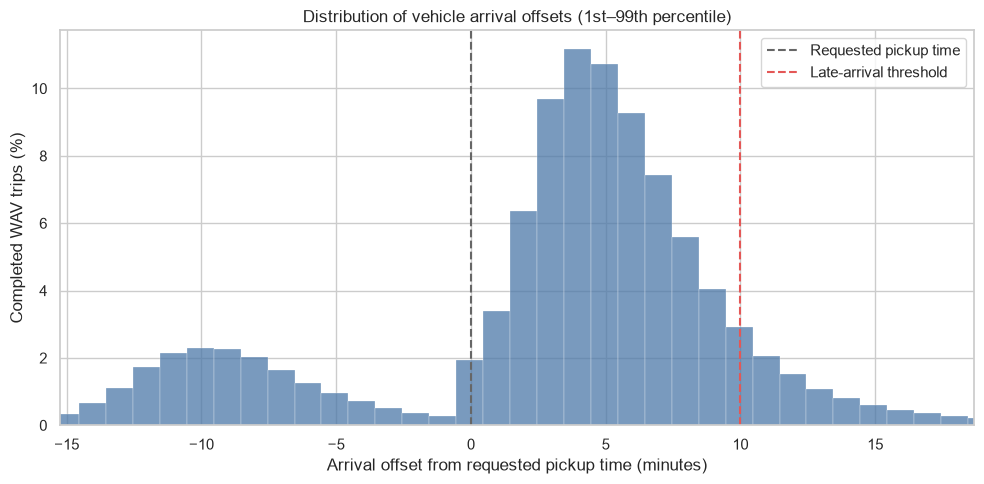

In [53]:
# Visualise the central arrival-offset distribution
arrival_offset_plot_df = (
    development_wav_requests_df
    .select("arrival_offset_minutes")
    .toPandas()
)

figure, axis = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=arrival_offset_plot_df,
    x="arrival_offset_minutes",
    binwidth=1,
    stat="percent",
    color="#4C78A8",
    ax=axis,
)

axis.axvline(
    0,
    color="#666666",
    linestyle="--",
    linewidth=1.5,
    label="Requested pickup time",
)

axis.axvline(
    LATE_THRESHOLD_MINUTES,
    color="#E45756",
    linestyle="--",
    linewidth=1.5,
    label="Late-arrival threshold",
)

axis.set_xlim(
    offset_profile_record["p01_minutes"],
    offset_profile_record["p99_minutes"],
)

axis.set_xlabel(
    "Arrival offset from requested pickup time (minutes)"
)
axis.set_ylabel("Completed WAV trips (%)")
axis.set_title(
    "Distribution of vehicle arrival offsets "
    "(1st–99th percentile)"
)
axis.legend()

figure.tight_layout()
plt.show()


### Monthly volume and service risk

Compare monthly completed-request volume with the late-arrival share.

In [54]:
# Aggregate completed requests and late trips by calendar month
monthly_service_risk_df = (
    development_wav_requests_df
    .groupBy(
        F.date_trunc(
            "month",
            F.col("requested_pickup_datetime"),
        ).alias("month_start")
    )
    .agg(
        F.count("*").alias("wav_request_count"),
        F.sum("late_10").alias("late_trip_count"),
    )
    .orderBy("month_start")
    .toPandas()
)
monthly_service_risk_df["late_share"] = (
    monthly_service_risk_df["late_trip_count"]
    / monthly_service_risk_df["wav_request_count"]
)
monthly_service_risk_df["month_label"] = (
    monthly_service_risk_df["month_start"].dt.strftime("%b")
)

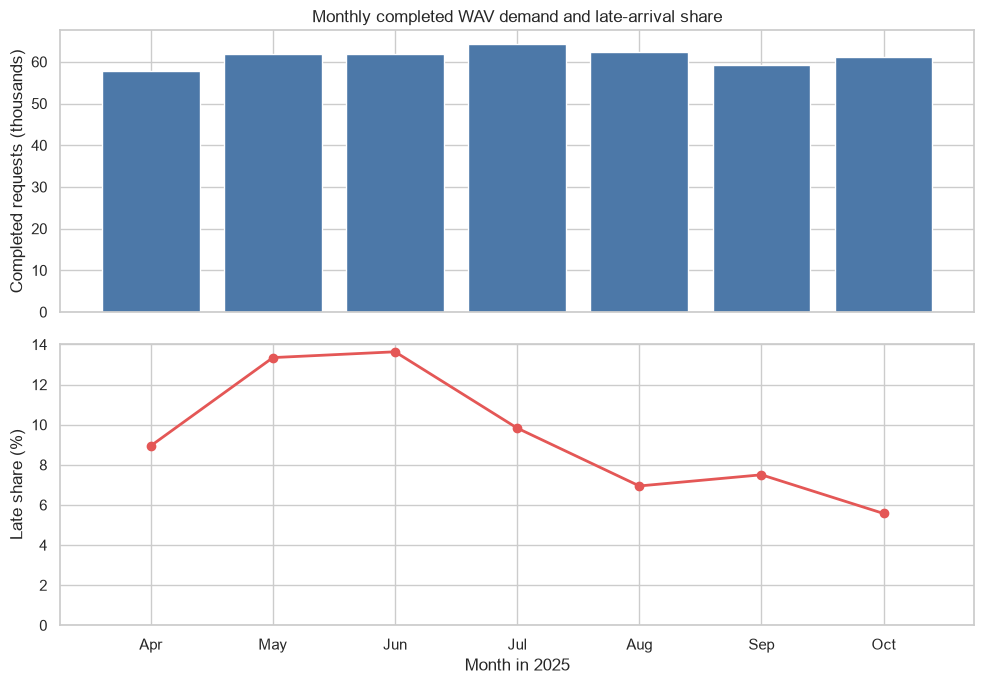

In [55]:
figure, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(10, 7),
    sharex=True,
)
axes[0].bar(
    monthly_service_risk_df["month_label"],
    monthly_service_risk_df["wav_request_count"] / 1_000,
    color="#4C78A8",
)
axes[0].set_ylabel("Completed requests (thousands)")
axes[0].set_title("Monthly completed WAV demand and late-arrival share")

axes[1].plot(
    monthly_service_risk_df["month_label"],
    100 * monthly_service_risk_df["late_share"],
    color="#E45756",
    marker="o",
    linewidth=2,
)
axes[1].set_xlabel("Month in 2025")
axes[1].set_ylabel("Late share (%)")
axes[1].set_ylim(bottom=0)
figure.tight_layout()
save_report_figure(figure, "wav_monthly_service_risk")
plt.show()

### Borough and time-block patterns

Compare count-weighted late shares across pickup boroughs and four-hour target periods.

In [56]:
# Pool counts before calculating request-weighted subgroup late shares
borough_time_risk_df = (
    development_panel_df
    .groupby(
        ["borough", "time_block"],
        as_index=False,
        observed=True,
    )[["wav_request_count", "late_trip_count"]]
    .sum()
)
borough_time_risk_df["late_share"] = (
    borough_time_risk_df["late_trip_count"]
    / borough_time_risk_df["wav_request_count"]
)

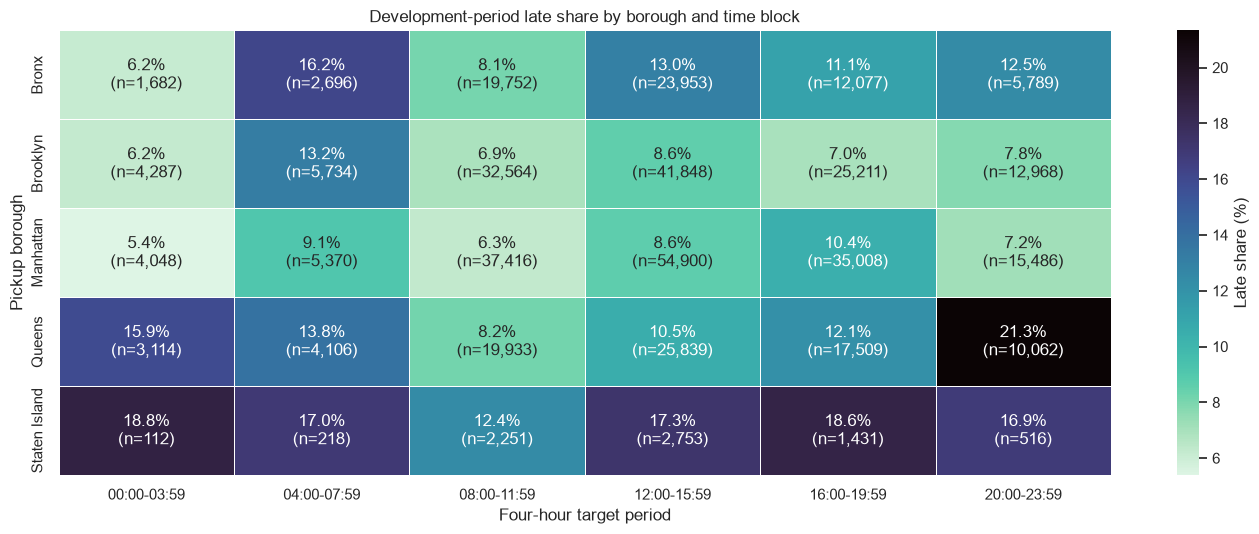

In [57]:
# Build aligned late-share and request-support matrices
borough_time_rate_matrix = (
    borough_time_risk_df
    .pivot(index="borough", columns="time_block", values="late_share")
    .reindex(index=NYC_BOROUGHS, columns=TIME_BLOCK_ORDER)
)
borough_time_count_matrix = (
    borough_time_risk_df
    .pivot(
        index="borough",
        columns="time_block",
        values="wav_request_count",
    )
    .reindex(index=NYC_BOROUGHS, columns=TIME_BLOCK_ORDER)
)
# Show both rate and support so sparse cells are not over-interpreted
borough_time_annotations = np.empty(
    borough_time_rate_matrix.shape,
    dtype=object,
)
for row_index, borough in enumerate(NYC_BOROUGHS):
    for column_index, time_block in enumerate(TIME_BLOCK_ORDER):
        late_share = borough_time_rate_matrix.loc[
            borough,
            time_block,
        ]
        request_count = int(
            borough_time_count_matrix.loc[borough, time_block]
        )
        borough_time_annotations[row_index, column_index] = (
            f"{late_share:.1%}\n(n={request_count:,})"
        )

figure, axis = plt.subplots(figsize=(14, 5.5))
sns.heatmap(
    100 * borough_time_rate_matrix,
    annot=borough_time_annotations,
    fmt="",
    cmap="mako_r",
    linewidths=0.5,
    cbar_kws={"label": "Late share (%)"},
    ax=axis,
)
axis.set_xlabel("Four-hour target period")
axis.set_ylabel("Pickup borough")
axis.set_title("Development-period late share by borough and time block")
figure.tight_layout()
save_report_figure(figure, "wav_borough_time_risk")
plt.show()

### Weather context

Compare late shares under normal and adverse weather for periods with complete hourly coverage.

In [58]:
# Use only observed targets with complete four-hour weather coverage
weather_risk_input_df = development_panel_df.loc[
    development_panel_df["target_observed"]
    & development_panel_df["weather_coverage_share"].eq(1)
].copy()
# Apply the fixed precipitation, visibility, and wind thresholds
weather_risk_input_df["adverse_weather"] = (
    weather_risk_input_df["observed_any_precipitation"].eq(True)
    | weather_risk_input_df["observed_min_visibility_km"].lt(
        ADVERSE_VISIBILITY_THRESHOLD_KM
    )
    | weather_risk_input_df["observed_max_wind_speed_ms"].ge(
        ADVERSE_WIND_THRESHOLD_MS
    )
)
weather_risk_input_df["weather_category"] = np.where(
    weather_risk_input_df["adverse_weather"],
    "Adverse",
    "Normal",
)
weather_risk_summary_df = (
    weather_risk_input_df
    .groupby("weather_category", as_index=False)[
        ["wav_request_count", "late_trip_count"]
    ]
    .sum()
)
weather_risk_summary_df["late_share"] = (
    weather_risk_summary_df["late_trip_count"]
    / weather_risk_summary_df["wav_request_count"]
)
weather_risk_summary_df

,weather_category,wav_request_count,late_trip_count,late_share
0,Adverse,80424,9360,0.1164
1,Normal,336180,30136,0.0896


## 6.2 Taxi Zone geospatial evidence

Map development-period Taxi Zone support and late shares across the five NYC boroughs, displaying sub-threshold zones in neutral grey while retaining borough × four-hour periods as the forecasting unit.

In [59]:
# Aggregate request support and late outcomes at pickup-zone level
zone_risk_summary_df = (
    development_wav_requests_df
    .groupBy("pickup_location_id")
    .agg(
        F.count("*").alias("wav_request_count"),
        F.sum("late_10").alias("late_trip_count"),
    )
    .orderBy("pickup_location_id")
    .toPandas()
)
zone_risk_summary_df["late_share"] = (
    zone_risk_summary_df["late_trip_count"]
    / zone_risk_summary_df["wav_request_count"]
)
zone_risk_summary_df["meets_support_threshold"] = (
    zone_risk_summary_df["wav_request_count"]
    >= MIN_ZONE_REQUEST_COUNT
)

In [60]:
# Restrict the map to the five-borough study geography before joining outcomes
study_taxi_zones_gdf = (
    taxi_zones_gdf
    .loc[taxi_zones_gdf["pickup_borough"].isin(NYC_BOROUGHS)]
    .copy()
)
# Left-join outcomes so in-scope zones with no observed requests remain visible
zone_risk_map_gdf = study_taxi_zones_gdf.merge(
    zone_risk_summary_df[
        [
            "pickup_location_id",
            "wav_request_count",
            "late_trip_count",
            "late_share",
            "meets_support_threshold",
        ]
    ],
    on="pickup_location_id",
    how="left",
)
zone_risk_map_gdf[["wav_request_count", "late_trip_count"]] = (
    zone_risk_map_gdf[
        ["wav_request_count", "late_trip_count"]
    ]
    .fillna(0)
    .astype("int64")
)
zone_risk_map_gdf["meets_support_threshold"] = (
    zone_risk_map_gdf["wav_request_count"]
    >= MIN_ZONE_REQUEST_COUNT
)
# Mask late shares that do not meet the minimum support rule
zone_risk_map_gdf["late_share_display_pct"] = np.where(
    zone_risk_map_gdf["meets_support_threshold"],
    100 * zone_risk_map_gdf["late_share"],
    np.nan,
)

supported_zone_count = int(
    zone_risk_map_gdf["meets_support_threshold"].sum()
)
supported_request_share = (
    zone_risk_map_gdf.loc[
        zone_risk_map_gdf["meets_support_threshold"],
        "wav_request_count",
    ].sum()
    / development_trip_count
)
print(
    f"Zones meeting the {MIN_ZONE_REQUEST_COUNT}-request rule: "
    f"{supported_zone_count:,} of {len(zone_risk_map_gdf):,}"
)
print(
    "Requests represented in the displayed risk map: "
    f"{supported_request_share:.2%}"
)

Zones meeting the 100-request rule: 241 of 262
Requests represented in the displayed risk map: 99.85%


findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


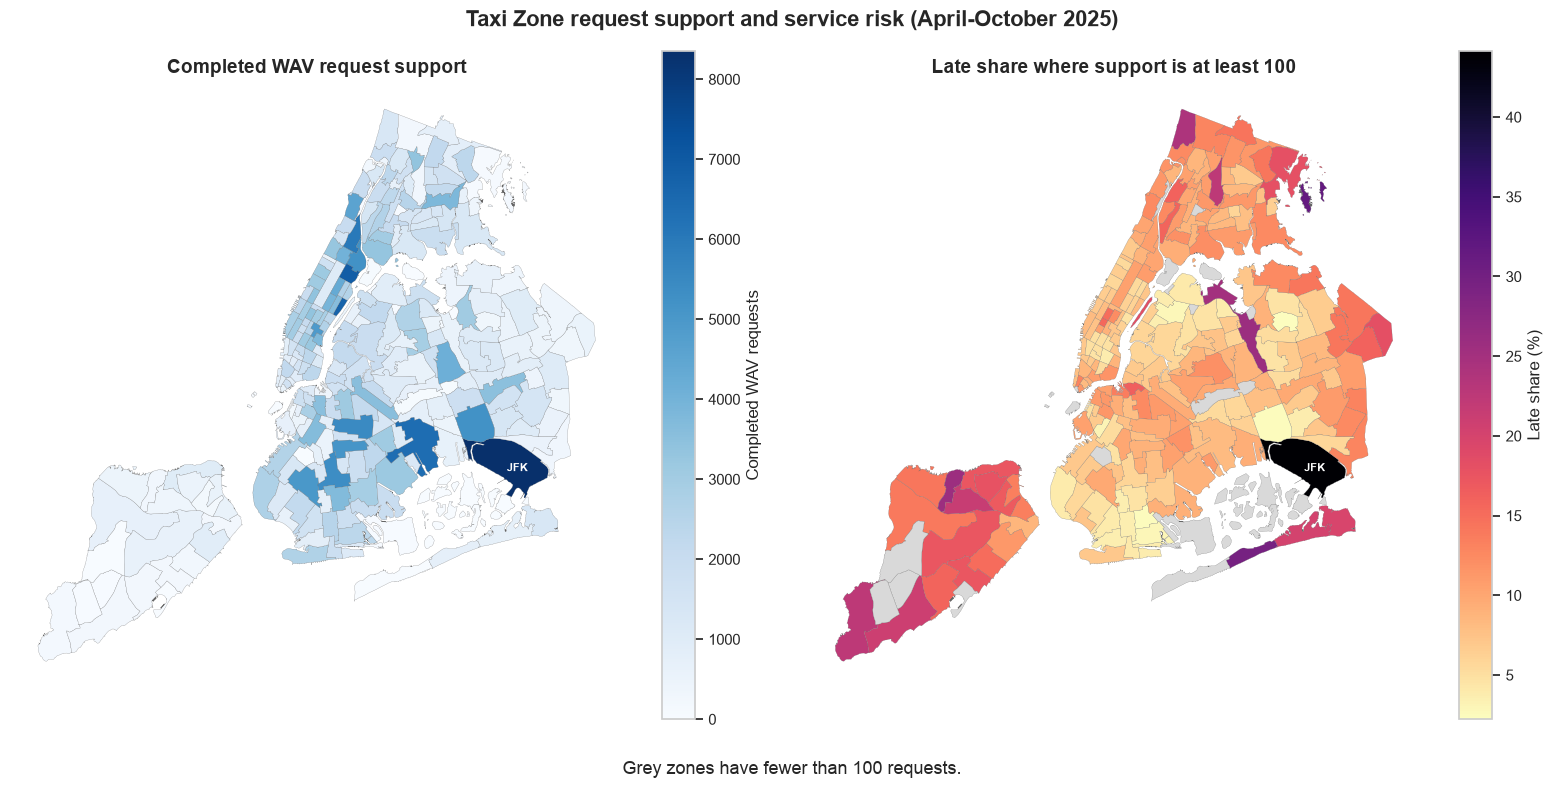

DataFrame[requested_pickup_datetime: timestamp_ntz, on_scene_datetime: timestamp_ntz, pickup_datetime: timestamp_ntz, pickup_location_id: int, pickup_zone: string, pickup_borough: string, arrival_offset_minutes: double, late_10: int, period_start: timestamp_ntz, month: int]

In [61]:
# Display request support beside late share to expose sparse zones
figure, axes = plt.subplots(1, 2, figsize=(16, 8))
zone_risk_map_gdf.plot(
    column="wav_request_count",
    cmap="Blues",
    linewidth=0.15,
    edgecolor="#666666",
    legend=True,
    legend_kwds={"label": "Completed WAV requests"},
    ax=axes[0],
)
axes[0].set_title(
    "Completed WAV request support",
    fontsize=14,
    fontweight="semibold",
)
axes[0].set_axis_off()

zone_risk_map_gdf.plot(
    column="late_share_display_pct",
    cmap="magma_r",
    linewidth=0.15,
    edgecolor="#666666",
    legend=True,
    legend_kwds={"label": "Late share (%)"},
    missing_kwds={
        "color": "#D9D9D9",
        "label": f"Fewer than {MIN_ZONE_REQUEST_COUNT} requests",
    },
    ax=axes[1],
)
axes[1].set_title(
    f"Late share where support is at least {MIN_ZONE_REQUEST_COUNT}",
    fontsize=14,
    fontweight="semibold",
)
axes[1].set_axis_off()

# Label the key high-support, high-risk zone in both panels
jfk_geometry = zone_risk_map_gdf.loc[
    zone_risk_map_gdf["pickup_zone"].eq("JFK Airport"),
    "geometry",
].iloc[0]
jfk_label_point = jfk_geometry.representative_point()
for axis in axes:
    axis.text(
        jfk_label_point.x,
        jfk_label_point.y,
        "JFK",
        color="white",
        fontsize=8,
        fontweight="bold",
        ha="center",
        va="center",
    )

figure.suptitle(
    "Taxi Zone request support and service risk (April-October 2025)",
    fontsize=16,
    fontweight="semibold",
)
figure.text(
    0.5,
    0.025,
    f"Grey zones have fewer than {MIN_ZONE_REQUEST_COUNT} requests.",
    ha="center",
    fontsize=13,
)
figure.tight_layout(rect=(0, 0.06, 1, 1))
save_report_figure(figure, "wav_taxi_zone_support_and_risk")
plt.show()

development_wav_requests_df.unpersist()

# 7. Forecast design, feature engineering, and benchmark

Define the chronological split, forecast-time feature contracts, issue-time
HRRR alignment, matured-history benchmark, and evaluation metrics before
fitting either model family.


## 7.1 Chronological split and frozen feature contracts

Issue each rolling one-period-ahead forecast at the target-period start.
Completed-trip features use the lag-2 maturity rule. Both models use the
same calendar, matured-history, and target-period HRRR forecasts whose run
was available at least three hours before issue time.


### Shared model information set

The grouped-binomial GLM and weighted XGBoost use the same numerical
predictors and model-specific representations of the categorical context.
A later XGBoost ablation removes only the HRRR forecasts to assess their
incremental contribution without changing the main model comparison.


In [62]:
# Separate row identifiers and observed outcomes from predictors
MODEL_KEY_COLUMNS = (
    "period_start",
    "borough",
    "split_label",
)
MODEL_TARGET_COLUMNS = (
    "wav_request_count",
    "late_trip_count",
    "late_share",
)

# Use model-specific representations of the same categorical context
GLM_CATEGORICAL_FEATURES = (
    "borough_time_block",
    "day_of_week",
    "is_holiday",
)
XGB_CATEGORICAL_FEATURES = (
    "borough",
    "time_block",
    "day_of_week",
    "is_holiday",
)

CALENDAR_MODEL_FEATURES = (
    "day_of_year_sin",
    "day_of_year_cos",
    "days_since_analysis_start",
)
HISTORICAL_MODEL_FEATURES = (
    "log1p_lag_2_wav_request_count",
    "log1p_rolling_24h_wav_request_count",
    "log1p_lag_2_citywide_wav_request_count",
    "lag_2_late_share",
    "rolling_24h_late_share",
    "rolling_7d_late_share",
    "historical_same_slot_late_share",
    "lag_2_late_share_available",
    "rolling_24h_late_share_available",
    "rolling_7d_late_share_available",
    "same_slot_late_share_available",
)
HRRR_SOURCE_WEATHER_COLUMNS = (
    "temperature_2m_c",
    "relative_humidity_2m_pct",
    "precipitation_rate_mm_per_hour",
    "categorical_rain",
    "wind_speed_10m_ms",
    "wind_gust_ms",
)
HRRR_FORECAST_MODEL_FEATURES = (
    "hrrr_forecast_mean_temperature_c",
    "hrrr_forecast_mean_relative_humidity_pct",
    "hrrr_forecast_total_precipitation_mm",
    "hrrr_forecast_any_rain",
    "hrrr_forecast_mean_wind_speed_ms",
    "hrrr_forecast_max_wind_gust_ms",
)
WITHOUT_HRRR_NUMERIC_MODEL_FEATURES = (
    *CALENDAR_MODEL_FEATURES,
    *HISTORICAL_MODEL_FEATURES,
)
MODEL_NUMERIC_FEATURES = (
    *WITHOUT_HRRR_NUMERIC_MODEL_FEATURES,
    *HRRR_FORECAST_MODEL_FEATURES,
)
ALL_MODEL_PREDICTOR_COLUMNS = tuple(
    dict.fromkeys(
        GLM_CATEGORICAL_FEATURES
        + XGB_CATEGORICAL_FEATURES
        + MODEL_NUMERIC_FEATURES
    )
)
PANEL_MODEL_PREDICTOR_COLUMNS = tuple(
    feature_name
    for feature_name in ALL_MODEL_PREDICTOR_COLUMNS
    if feature_name != "borough_time_block"
)


In [63]:
# List any contemporaneous outcomes or context in the predictor set
FORBIDDEN_PREDICTOR_COLUMNS = {
    "wav_request_count",
    "late_trip_count",
    "late_share",
    "target_observed",
    "citywide_wav_request_count",
    "observed_mean_temperature_c",
    "observed_max_wind_speed_ms",
    "observed_min_visibility_km",
    "observed_any_precipitation",
    "observed_any_rain",
    "observed_any_snow",
}
leaking_predictors = FORBIDDEN_PREDICTOR_COLUMNS.intersection(
    ALL_MODEL_PREDICTOR_COLUMNS
)
leaking_predictors


set()

## 7.2 Issue-time HRRR feature engineering

Select the latest run satisfying `init_time + 3 hours <= period_start`,
then aggregate only that run's valid-time weather inside the target borough-
period. Run selection uses timestamps and forecast metadata only.


In [64]:
hrrr_forecast_source_df = pd.read_parquet(HRRR_COMBINED_PATH)
print(f"HRRR forecast rows: {len(hrrr_forecast_source_df):,}")


HRRR forecast rows: 270,970


In [65]:
# Standardise forecast timestamps before temporal alignment
hrrr_forecast_source_df = hrrr_forecast_source_df.copy()
for timestamp_column in ("init_time_utc", "valid_time_utc"):
    hrrr_forecast_source_df[timestamp_column] = pd.to_datetime(
        hrrr_forecast_source_df[timestamp_column],
        utc=True,
    )

hrrr_source_audit_df = pd.DataFrame(
    [
        {
            "forecast_rows": len(hrrr_forecast_source_df),
            "forecast_runs": hrrr_forecast_source_df[
                "init_time_utc"
            ].nunique(),
            "boroughs": hrrr_forecast_source_df[
                "borough"
            ].nunique(),
            "minimum_lead_hours": hrrr_forecast_source_df[
                "lead_time_hours"
            ].min(),
            "maximum_lead_hours": hrrr_forecast_source_df[
                "lead_time_hours"
            ].max(),
        }
    ]
)
hrrr_source_audit_df

,forecast_rows,forecast_runs,boroughs,minimum_lead_hours,maximum_lead_hours
0,270970,1106,5,0,48


In [66]:
# Build one target-period schedule without using target outcomes
hrrr_target_period_df = (
    saved_curated_wav_panel_df[["period_start"]]
    .drop_duplicates()
    .sort_values("period_start")
    .reset_index(drop=True)
)
hrrr_target_period_df["period_start"] = pd.to_datetime(
    hrrr_target_period_df["period_start"]
)
hrrr_target_period_df["period_end"] = (
    hrrr_target_period_df["period_start"]
    + pd.to_timedelta(PERIOD_HOURS, unit="h")
)
# Localise both boundaries separately to preserve daylight-saving changes
hrrr_target_period_df["period_start_utc"] = (
    hrrr_target_period_df["period_start"]
    .dt.tz_localize(TIMEZONE)
    .dt.tz_convert("UTC")
)
hrrr_target_period_df["period_end_utc"] = (
    hrrr_target_period_df["period_end"]
    .dt.tz_localize(TIMEZONE)
    .dt.tz_convert("UTC")
)
hrrr_target_period_df["forecast_availability_cutoff_utc"] = (
    hrrr_target_period_df["period_start_utc"]
    - pd.to_timedelta(
        HRRR_FORECAST_AVAILABILITY_BUFFER_HOURS,
        unit="h",
    )
)

hrrr_available_run_df = (
    hrrr_forecast_source_df[["init_time_utc"]]
    .drop_duplicates()
    .sort_values("init_time_utc")
)
hrrr_selected_run_df = pd.merge_asof(
    hrrr_target_period_df.sort_values(
        "forecast_availability_cutoff_utc"
    ),
    hrrr_available_run_df,
    left_on="forecast_availability_cutoff_utc",
    right_on="init_time_utc",
    direction="backward",
    allow_exact_matches=True,
).rename(columns={"init_time_utc": "selected_init_time_utc"})
hrrr_selected_run_df["forecast_age_hours"] = (
    hrrr_selected_run_df["period_start_utc"]
    - hrrr_selected_run_df["selected_init_time_utc"]
) / pd.to_timedelta(1, unit="h")

hrrr_selected_run_df[[
    "period_start",
    "selected_init_time_utc",
    "forecast_age_hours",
]].head()


,period_start,selected_init_time_utc,forecast_age_hours
0,2025-04-01 00:00:00,2025-04-01 00:00:00+00:00,4.0000
1,2025-04-01 04:00:00,2025-04-01 00:00:00+00:00,8.0000
2,2025-04-01 08:00:00,2025-04-01 06:00:00+00:00,6.0000
3,2025-04-01 12:00:00,2025-04-01 12:00:00+00:00,4.0000
4,2025-04-01 16:00:00,2025-04-01 12:00:00+00:00,8.0000


In [67]:
# Expand target periods to boroughs, then join only the selected run
hrrr_borough_df = (
    saved_curated_wav_panel_df[["borough"]]
    .drop_duplicates()
    .sort_values("borough")
)
hrrr_borough_period_df = hrrr_selected_run_df.merge(
    hrrr_borough_df,
    how="cross",
)
hrrr_selected_source_df = hrrr_forecast_source_df.rename(
    columns={"init_time_utc": "selected_init_time_utc"}
)
# One run can serve adjacent periods before valid-time filtering
hrrr_target_hourly_df = hrrr_borough_period_df.merge(
    hrrr_selected_source_df,
    on=["selected_init_time_utc", "borough"],
    how="left",
)
hrrr_target_hourly_df = hrrr_target_hourly_df.loc[
    hrrr_target_hourly_df["valid_time_utc"].ge(
        hrrr_target_hourly_df["period_start_utc"]
    )
    & hrrr_target_hourly_df["valid_time_utc"].lt(
        hrrr_target_hourly_df["period_end_utc"]
    )
].copy()
hrrr_period_key_columns = ("period_start", "borough")
hrrr_actual_hour_count = hrrr_target_hourly_df.groupby(
    list(hrrr_period_key_columns),
    observed=True,
).size()
hrrr_expected_hour_count = (
    hrrr_borough_period_df.set_index(list(hrrr_period_key_columns))[
        "period_end_utc"
    ]
    - hrrr_borough_period_df.set_index(list(hrrr_period_key_columns))[
        "period_start_utc"
    ]
) / pd.to_timedelta(1, unit="h")
hrrr_expected_hour_count = hrrr_expected_hour_count.astype(int)
hrrr_hour_count_comparison_df = pd.concat(
    [
        hrrr_expected_hour_count.rename("expected_hour_count"),
        hrrr_actual_hour_count.rename("actual_hour_count"),
    ],
    axis=1,
)
hrrr_hour_count_comparison_df.value_counts().sort_index()


expected_hour_count  actual_hour_count
4                    4                    8245
5                    5                       5
Name: count, dtype: int64

In [68]:
# Aggregate valid-time forecasts into one feature row per borough-period
hrrr_forecast_feature_df = (
    hrrr_target_hourly_df.groupby(
        list(hrrr_period_key_columns),
        observed=True,
    )
    .agg(
        hrrr_forecast_mean_temperature_c=(
            "temperature_2m_c",
            "mean",
        ),
        hrrr_forecast_mean_relative_humidity_pct=(
            "relative_humidity_2m_pct",
            "mean",
        ),
        hrrr_forecast_total_precipitation_mm=(
            "precipitation_rate_mm_per_hour",
            "sum",
        ),
        hrrr_forecast_any_rain=("categorical_rain", "max"),
        hrrr_forecast_mean_wind_speed_ms=(
            "wind_speed_10m_ms",
            "mean",
        ),
        hrrr_forecast_max_wind_gust_ms=("wind_gust_ms", "max"),
        hrrr_selected_init_time_utc=("selected_init_time_utc", "first"),
        hrrr_forecast_age_hours=("forecast_age_hours", "first"),
        hrrr_forecast_hour_count=("valid_time_utc", "size"),
        hrrr_minimum_lead_hours=("lead_time_hours", "min"),
        hrrr_maximum_lead_hours=("lead_time_hours", "max"),
    )
    .reset_index()
)
hrrr_feature_engineering_audit_df = pd.DataFrame(
    [
        {
            "borough_period_rows": len(hrrr_forecast_feature_df),
            "minimum_forecast_age_hours": hrrr_forecast_feature_df[
                "hrrr_forecast_age_hours"
            ].min(),
            "maximum_forecast_age_hours": hrrr_forecast_feature_df[
                "hrrr_forecast_age_hours"
            ].max(),
            "minimum_used_lead_hours": hrrr_forecast_feature_df[
                "hrrr_minimum_lead_hours"
            ].min(),
            "maximum_used_lead_hours": hrrr_forecast_feature_df[
                "hrrr_maximum_lead_hours"
            ].max(),
            "minimum_hour_count": hrrr_forecast_feature_df[
                "hrrr_forecast_hour_count"
            ].min(),
            "maximum_hour_count": hrrr_forecast_feature_df[
                "hrrr_forecast_hour_count"
            ].max(),
        }
    ]
)
hrrr_feature_engineering_audit_df


,borough_period_rows,minimum_forecast_age_hours,maximum_forecast_age_hours,minimum_used_lead_hours,maximum_used_lead_hours,minimum_hour_count,maximum_hour_count
0,8250,3.0000,8.0000,3,11,4,5


## 7.3 Model-ready chronological frames

Join the complete HRRR feature table one-to-one to the base panel. Keep
outcomes only in training and validation frames, and construct the future
evaluation frame from keys and forecast-time predictors alone.


In [69]:
def add_borough_time_block(data: pd.DataFrame) -> pd.DataFrame:
    """Add the pre-specified borough and four-hour interaction category."""
    enriched_data = data.copy()
    enriched_data["borough_time_block"] = (
        enriched_data["borough"].astype("string")
        + " | "
        + enriched_data["time_block"].astype("string")
    )
    return enriched_data


In [70]:
# Attach complete issue-time forecast features to the base panel
model_panel_df = saved_curated_wav_panel_df.merge(
    hrrr_forecast_feature_df[
        [
            *hrrr_period_key_columns,
            *HRRR_FORECAST_MODEL_FEATURES,
        ]
    ],
    on=list(hrrr_period_key_columns),
    how="left",
)
development_model_columns = tuple(
    dict.fromkeys(
        MODEL_KEY_COLUMNS
        + MODEL_TARGET_COLUMNS
        + PANEL_MODEL_PREDICTOR_COLUMNS
    )
)
future_feature_columns = tuple(
    dict.fromkeys(
        MODEL_KEY_COLUMNS + PANEL_MODEL_PREDICTOR_COLUMNS
    )
)

training_model_mask = (
    model_panel_df["split_label"].eq("training")
    & model_panel_df["target_observed"]
)
validation_model_mask = (
    model_panel_df["split_label"].eq("validation")
    & model_panel_df["target_observed"]
)
future_test_mask = model_panel_df["split_label"].eq("test")

model_training_df = add_borough_time_block(
    model_panel_df.loc[
        training_model_mask,
        development_model_columns,
    ]
)
model_validation_df = add_borough_time_block(
    model_panel_df.loc[
        validation_model_mask,
        development_model_columns,
    ]
)
future_test_features_df = add_borough_time_block(
    model_panel_df.loc[
        future_test_mask,
        future_feature_columns,
    ]
)
model_development_df = pd.concat(
    [model_training_df, model_validation_df],
    ignore_index=True,
)


In [71]:
split_summary_df = pd.DataFrame(
    [
        {
            "split": "Training",
            "period": "April-August 2025",
            "panel_rows": int(
                model_panel_df["split_label"].eq("training").sum()
            ),
            "scoreable_rows": len(model_training_df),
        },
        {
            "split": "Validation",
            "period": "September-October 2025",
            "panel_rows": int(
                model_panel_df["split_label"].eq("validation").sum()
            ),
            "scoreable_rows": len(model_validation_df),
        },
        {
            "split": "Chronological evaluation",
            "period": "November-December 2025",
            "panel_rows": len(future_test_features_df),
            "scoreable_rows": pd.NA,
        },
    ]
)
split_summary_df


,split,period,panel_rows,scoreable_rows
0,Training,April-August 2025,4590,4438
1,Validation,September-October 2025,1830,1734
2,Chronological evaluation,November-December 2025,1830,<NA>


## 7.4 Matured 24-hour history benchmark

Create a count-weighted forecast from the latest mature 24-hour history
ending four hours before issue time, with training-period borough and
citywide fallbacks.


In [72]:
# Estimate borough and citywide fallback risks from training data only
training_borough_fallback_df = (
    model_training_df
    .groupby("borough", as_index=False)
    .agg(
        late_trip_count=("late_trip_count", "sum"),
        wav_request_count=("wav_request_count", "sum"),
    )
)
training_borough_fallback_df["borough_training_late_share"] = (
    training_borough_fallback_df["late_trip_count"]
    / training_borough_fallback_df["wav_request_count"]
)
training_global_late_share = (
    model_training_df["late_trip_count"].sum()
    / model_training_df["wav_request_count"].sum()
)

In [73]:
BENCHMARK_PREDICTION_COLUMNS = {
    "Matured 24-hour history": "persistence_24h_prediction",
}
benchmark_source_columns = (
    *MODEL_KEY_COLUMNS,
    "rolling_24h_late_share",
)
# Assemble target-free validation and test rows for benchmark forecasts
benchmark_forecast_source_df = pd.concat(
    [
        model_validation_df.loc[:, benchmark_source_columns],
        future_test_features_df.loc[:, benchmark_source_columns],
    ],
    ignore_index=True,
)
benchmark_forecast_source_df = benchmark_forecast_source_df.merge(
    training_borough_fallback_df[
        ["borough", "borough_training_late_share"]
    ],
    on="borough",
    how="left",
)

# Fall back from matured 24-hour history to borough and global risk
borough_fallback_values = benchmark_forecast_source_df[
    "borough_training_late_share"
].fillna(training_global_late_share)
benchmark_forecast_source_df["persistence_24h_prediction"] = (
    benchmark_forecast_source_df["rolling_24h_late_share"]
    .fillna(borough_fallback_values)
)
benchmark_forecast_source_df["persistence_fallback_used"] = (
    benchmark_forecast_source_df["rolling_24h_late_share"].isna()
)

# Retain keys, forecasts, and the fallback audit flag only
benchmark_output_columns = (
    *MODEL_KEY_COLUMNS,
    *BENCHMARK_PREDICTION_COLUMNS.values(),
    "persistence_fallback_used",
)
benchmark_forecasts_df = (
    benchmark_forecast_source_df.loc[:, benchmark_output_columns]
    .sort_values(["period_start", "borough"])
    .reset_index(drop=True)
)

## 7.5 Evaluation criteria

Use request-weighted MAE as the primary comparison metric and retain
weighted RMSE, unweighted MAE, calibration, and subgroup diagnostics.


In [74]:
# Freeze calibration, screening, and robustness criteria
PRIMARY_SELECTION_METRIC = "weighted_mae"
HIGH_RISK_THRESHOLD = 0.10
CALIBRATION_BIN_COUNT = 10
TOP_RISK_CAPTURE_SHARE = 0.10
REQUEST_VOLUME_BIN_EDGES = (0, 10, 50, 100, np.inf)
REQUEST_VOLUME_BIN_LABELS = (
    "1-10 requests",
    "11-50 requests",
    "51-100 requests",
    "More than 100 requests",
)


In [75]:
def calculate_forecast_metrics(
    evaluation_data: pd.DataFrame,
    prediction_column: str,
    model_name: str,
    evaluation_group: str = "Overall",
) -> dict[str, float | int | str]:
    """
    Calculate count-weighted and unweighted forecast-error metrics.

    Args:
        evaluation_data: Scoreable rows with targets, weights, and forecasts.
        prediction_column: Column containing predicted late shares.
        model_name: Human-readable model or benchmark name.
        evaluation_group: Population label for the returned record.

    Returns:
        One metric record containing errors, calibration, and support.
    """
    # Align grouped outcomes, forecasts, and request-count weights
    observed_values = evaluation_data["late_share"].to_numpy(
        dtype=float
    )
    predicted_values = evaluation_data[prediction_column].to_numpy(
        dtype=float
    )
    request_weights = evaluation_data["wav_request_count"].to_numpy(
        dtype=float
    )
    split_label = str(evaluation_data["split_label"].iloc[0])

    # Use request-weighted MAE as primary, with supporting error measures
    weighted_mae = mean_absolute_error(
        observed_values,
        predicted_values,
        sample_weight=request_weights,
    )
    weighted_rmse = root_mean_squared_error(
        observed_values,
        predicted_values,
        sample_weight=request_weights,
    )
    unweighted_mae = mean_absolute_error(
        observed_values,
        predicted_values,
    )
    observed_weighted_share = np.average(
        observed_values,
        weights=request_weights,
    )
    predicted_weighted_share = np.average(
        predicted_values,
        weights=request_weights,
    )

    return {
        "model_name": model_name,
        "split_label": split_label,
        "evaluation_group": evaluation_group,
        "row_count": len(evaluation_data),
        "wav_request_count": int(request_weights.sum()),
        "weighted_mae": weighted_mae,
        "weighted_mae_percentage_points": 100 * weighted_mae,
        "weighted_rmse": weighted_rmse,
        "weighted_rmse_percentage_points": 100 * weighted_rmse,
        "unweighted_mae": unweighted_mae,
        "unweighted_mae_percentage_points": 100 * unweighted_mae,
        "observed_weighted_late_share": observed_weighted_share,
        "predicted_weighted_late_share": predicted_weighted_share,
        "calibration_gap_percentage_points": (
            100
            * (predicted_weighted_share - observed_weighted_share)
        ),
    }

In [76]:
def build_weighted_calibration_table(
    evaluation_data: pd.DataFrame,
    prediction_column: str,
    model_name: str,
    bin_count: int = CALIBRATION_BIN_COUNT,
) -> pd.DataFrame:
    """
    Summarise observed and predicted risk in weighted forecast-risk bins.

    Args:
        evaluation_data: Scoreable rows with grouped outcomes and forecasts.
        prediction_column: Column containing predicted late shares.
        model_name: Label recorded in the returned table.
        bin_count: Number of equal-row forecast-risk groups.

    Returns:
        One row per calibration bin with request-weighted risk estimates.
    """
    # Rank forecasts before forming equal-row risk bins
    calibration_data = evaluation_data.copy()
    forecast_ranks = calibration_data[prediction_column].rank(
        method="first"
    )
    calibration_data["calibration_bin"] = (
        pd.qcut(
            forecast_ranks,
            q=bin_count,
            labels=False,
        )
        + 1
    )
    # Weight predicted risk by completed-request support within each bin
    calibration_data["weighted_prediction_total"] = (
        calibration_data[prediction_column]
        * calibration_data["wav_request_count"]
    )

    calibration_table = (
        calibration_data
        .groupby("calibration_bin", as_index=False, observed=True)
        .agg(
            row_count=("period_start", "size"),
            wav_request_count=("wav_request_count", "sum"),
            late_trip_count=("late_trip_count", "sum"),
            mean_predicted_risk=(
                "weighted_prediction_total",
                "sum",
            ),
            minimum_prediction=(prediction_column, "min"),
            maximum_prediction=(prediction_column, "max"),
        )
    )
    calibration_table["observed_late_share"] = (
        calibration_table["late_trip_count"]
        / calibration_table["wav_request_count"]
    )
    calibration_table["predicted_late_share"] = (
        calibration_table["mean_predicted_risk"]
        / calibration_table["wav_request_count"]
    )
    calibration_table.insert(0, "model_name", model_name)
    return calibration_table.drop(columns="mean_predicted_risk")

In [77]:
# Join validation outcomes to the target-free history benchmark
validation_benchmark_scoring_df = (
    model_validation_df[
        [*MODEL_KEY_COLUMNS, *MODEL_TARGET_COLUMNS]
    ]
    .merge(
        benchmark_forecasts_df.loc[
            benchmark_forecasts_df["split_label"].eq("validation")
        ],
        on=list(MODEL_KEY_COLUMNS),
        how="left",
    )
)

validation_benchmark_metrics_df = pd.DataFrame(
    [
        calculate_forecast_metrics(
            validation_benchmark_scoring_df,
            prediction_column,
            benchmark_name,
        )
        for benchmark_name, prediction_column in (
            BENCHMARK_PREDICTION_COLUMNS.items()
        )
    ]
)
validation_benchmark_metrics_df[
    [
        "model_name",
        "weighted_mae_percentage_points",
        "weighted_rmse_percentage_points",
        "unweighted_mae_percentage_points",
    ]
]

,model_name,weighted_mae_percentage_points,weighted_rmse_percentage_points,unweighted_mae_percentage_points
0,Matured 24-hour history,2.9676,4.3203,5.4294


# 8. Model training and validation

Fit one grouped-binomial GLM and one weighted XGBoost using the shared
model information set. Validation compares the model families and freezes
the XGBoost tree count before chronological evaluation.


## 8.1 Model 1: Grouped Binomial Logistic Regression

Model each borough-period through its grouped late and on-time completed-trip counts using a binomial likelihood.

### 8.1.1 Model specification

Fit training-only imputation, scaling, and reference-level encoding before
constructing a full-rank grouped-binomial design matrix.


In [78]:
GLM_MODEL_NAME = "Grouped Binomial GLM"
XGB_MODEL_NAME = "Weighted XGBoost"
GLM_CLUSTER_FREQUENCY = "W-SUN"

model_feature_contract_df = pd.DataFrame(
    [
        {
            "model_name": GLM_MODEL_NAME,
            "categorical_feature_count": len(
                GLM_CATEGORICAL_FEATURES
            ),
            "numeric_feature_count": len(MODEL_NUMERIC_FEATURES),
        },
        {
            "model_name": XGB_MODEL_NAME,
            "categorical_feature_count": len(
                XGB_CATEGORICAL_FEATURES
            ),
            "numeric_feature_count": len(MODEL_NUMERIC_FEATURES),
        },
    ]
)
model_feature_contract_df


,model_name,categorical_feature_count,numeric_feature_count
0,Grouped Binomial GLM,3,20
1,Weighted XGBoost,4,20


In [79]:
def build_model_preprocessor(
    categorical_features: tuple[str, ...],
    numeric_features: tuple[str, ...],
    *,
    standardise_numeric: bool,
    drop_first_category: bool,
) -> ColumnTransformer:
    """
    Build a training-fitted preprocessing pipeline for model predictors.

    Args:
        categorical_features: Categorical columns to impute and encode.
        numeric_features: Numerical columns to impute and optionally scale.
        standardise_numeric: Whether to centre and scale numerical columns.
        drop_first_category: Whether to omit one reference category per factor.

    Returns:
        An unfitted column transformer with deterministic feature names.
    """
    # Impute and one-hot encode categories using training data only
    categorical_pipeline = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(strategy="most_frequent"),
            ),
            (
                "encoder",
                OneHotEncoder(
                    drop="first" if drop_first_category else None,
                    sparse_output=False,
                ),
            ),
        ]
    )

    # Median-impute numeric fields and scale them only when requested
    numeric_steps = [
        (
            "imputer",
            SimpleImputer(strategy="median"),
        )
    ]
    if standardise_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    # Preserve readable output feature names for model interpretation
    return ColumnTransformer(
        transformers=[
            (
                "categorical",
                categorical_pipeline,
                list(categorical_features),
            ),
            ("numeric", Pipeline(numeric_steps), list(numeric_features)),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

In [80]:
def build_grouped_binomial_outcome(
    modelling_data: pd.DataFrame,
) -> np.ndarray:
    """
    Construct explicit grouped late and on-time counts for a binomial GLM.

    Args:
        modelling_data: Scoreable borough-period rows with grouped counts.

    Returns:
        A two-column array containing late and on-time completed trips.
    """
    late_counts = modelling_data["late_trip_count"].to_numpy(dtype=float)
    request_counts = modelling_data["wav_request_count"].to_numpy(
        dtype=float
    )
    # A grouped binomial outcome stores event and non-event counts
    on_time_counts = request_counts - late_counts

    return np.column_stack([late_counts, on_time_counts])

In [81]:
def fit_grouped_binomial_model(
    fitting_data: pd.DataFrame,
    prediction_data: pd.DataFrame,
    categorical_features: tuple[str, ...],
    numeric_features: tuple[str, ...],
) -> dict[str, object]:
    """
    Fit a grouped-binomial GLM and predict a later chronological period.

    The encoder, imputer, and scaler are fitted only on fitting_data. Weekly
    cluster-robust covariance is used for coefficient uncertainty, while
    predictions follow the grouped-binomial mean model.

    Args:
        fitting_data: Rows containing predictors and grouped outcomes.
        prediction_data: Later rows requiring probability forecasts.
        categorical_features: Frozen categorical predictors.
        numeric_features: Frozen numerical predictors.

    Returns:
        Fitted preprocessing and GLM objects, forecasts, and diagnostics.
    """
    # Fit all preprocessing on the historical fitting rows only
    predictor_columns = (*categorical_features, *numeric_features)
    preprocessor = build_model_preprocessor(
        categorical_features,
        numeric_features,
        standardise_numeric=True,
        drop_first_category=True,
    )
    fitting_matrix = preprocessor.fit_transform(
        fitting_data.loc[:, predictor_columns]
    )
    prediction_matrix = preprocessor.transform(
        prediction_data.loc[:, predictor_columns]
    )
    feature_names = tuple(preprocessor.get_feature_names_out())

    # Construct named design matrices and add the intercept explicitly
    fitting_design = pd.DataFrame(
        fitting_matrix,
        columns=feature_names,
        index=fitting_data.index,
    )
    prediction_design = pd.DataFrame(
        prediction_matrix,
        columns=feature_names,
        index=prediction_data.index,
    )
    fitting_design = sm.add_constant(
        fitting_design,
        has_constant="add",
    )
    prediction_design = sm.add_constant(
        prediction_design,
        has_constant="add",
    )

    # Remove exact duplicate columns so the GLM design is estimable
    duplicate_column_mask = fitting_design.T.duplicated(
        keep="first"
    )
    dropped_duplicate_columns = tuple(
        fitting_design.columns[duplicate_column_mask]
    )
    fitting_design = fitting_design.loc[:, ~duplicate_column_mask]
    prediction_design = prediction_design.loc[
        :, ~duplicate_column_mask
    ]

    design_rank = int(
        np.linalg.matrix_rank(fitting_design.to_numpy(dtype=float))
    )
    # Cluster coefficient uncertainty by calendar week
    grouped_outcome = build_grouped_binomial_outcome(fitting_data)
    cluster_groups = (
        fitting_data["period_start"]
        .dt.to_period(GLM_CLUSTER_FREQUENCY)
        .astype(str)
    )
    glm_model = sm.GLM(
        endog=grouped_outcome,
        exog=fitting_design,
        family=sm.families.Binomial(),
    )
    glm_result = glm_model.fit(
        cov_type="cluster",
        cov_kwds={"groups": cluster_groups},
    )

    # Generate later-period probability forecasts
    predicted_probabilities = np.asarray(
        glm_result.predict(prediction_design),
        dtype=float,
    )
    pearson_dispersion = float(
        np.square(glm_result.resid_pearson).sum()
        / glm_result.df_resid
    )
    return {
        "preprocessor": preprocessor,
        "result": glm_result,
        "fitting_design": fitting_design,
        "prediction_design": prediction_design,
        "predictions": predicted_probabilities,
        "design_rank": design_rank,
        "parameter_count": fitting_design.shape[1],
        "cluster_count": int(cluster_groups.nunique()),
        "dropped_duplicate_columns": (
            dropped_duplicate_columns
        ),
        "pearson_dispersion": pearson_dispersion,
    }

In [82]:
GLM_VALIDATION_PREDICTION_COLUMN = "glm_validation_prediction"

glm_validation_fit = fit_grouped_binomial_model(
    fitting_data=model_training_df,
    prediction_data=model_validation_df,
    categorical_features=GLM_CATEGORICAL_FEATURES,
    numeric_features=MODEL_NUMERIC_FEATURES,
)
glm_validation_scoring_df = model_validation_df[
    [*MODEL_KEY_COLUMNS, *MODEL_TARGET_COLUMNS]
].copy()
glm_validation_scoring_df[GLM_VALIDATION_PREDICTION_COLUMN] = (
    glm_validation_fit["predictions"]
)
glm_validation_metric_record = calculate_forecast_metrics(
    glm_validation_scoring_df,
    GLM_VALIDATION_PREDICTION_COLUMN,
    GLM_MODEL_NAME,
)
glm_validation_metric_record.update(
    {
        "parameter_count": glm_validation_fit["parameter_count"],
        "selected_tree_count": pd.NA,
    }
)


In [83]:
glm_validation_metrics_df = pd.DataFrame(
    [glm_validation_metric_record]
)
glm_validation_metrics_df[
    [
        "model_name",
        "weighted_mae_percentage_points",
        "weighted_rmse_percentage_points",
        "parameter_count",
    ]
]


,model_name,weighted_mae_percentage_points,weighted_rmse_percentage_points,parameter_count
0,Grouped Binomial GLM,2.6065,3.7541,56


## 8.2 Model 2: Weighted XGBoost

Fit a nonlinear logistic-objective XGBoost regressor using completed-request
counts as observation weights.


### 8.2.1 Validation and early stopping

Use the frozen regularised hyperparameters with validation-based early
stopping. The selected tree count is fixed before chronological evaluation.


In [84]:
XGB_N_JOBS = 4
XGB_MAX_ESTIMATORS = 3000
XGB_EARLY_STOPPING_ROUNDS = 100
XGB_REGULARISED_CONFIGURATION = {
    "max_depth": 2,
    "learning_rate": 0.05,
    "min_child_weight": 20,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_lambda": 5,
}


In [85]:
def build_xgboost_model(
    configuration: dict[str, float | int | str],
    n_estimators: int,
    early_stopping_rounds: int | None = None,
) -> XGBRegressor:
    """
    Build an XGBoost regressor from one frozen configuration.

    Args:
        configuration: Frozen feature and hyperparameter settings.
        n_estimators: Maximum or selected number of boosting trees.
        early_stopping_rounds: Optional validation stopping patience.

    Returns:
        An unfitted, reproducibly configured XGBoost estimator.
    """
    model_parameters = {
        "objective": "reg:logistic",
        "n_estimators": n_estimators,
        "eval_metric": "mae",
        "random_state": RANDOM_SEED,
        "n_jobs": XGB_N_JOBS,
        "tree_method": "hist",
        "max_depth": configuration["max_depth"],
        "learning_rate": configuration["learning_rate"],
        "min_child_weight": configuration["min_child_weight"],
        "subsample": configuration["subsample"],
        "colsample_bytree": configuration["colsample_bytree"],
        "reg_lambda": configuration["reg_lambda"],
    }
    # Add validation-based stopping only when early stopping is requested
    if early_stopping_rounds is not None:
        model_parameters["early_stopping_rounds"] = (
            early_stopping_rounds
        )
    return XGBRegressor(**model_parameters)

In [86]:
def fit_xgboost_validation_model(
    fitting_data: pd.DataFrame,
    prediction_data: pd.DataFrame,
    categorical_features: tuple[str, ...],
    numeric_features: tuple[str, ...],
    configuration: dict[str, float | int | str],
) -> dict[str, object]:
    """Fit one weighted XGBoost validation model with early stopping.

    Args:
        fitting_data: April-August scoreable rows.
        prediction_data: September-October scoreable rows.
        categorical_features: Frozen categorical predictors.
        numeric_features: Frozen numerical predictors.
        configuration: Frozen regularised hyperparameters.

    Returns:
        Fitted preprocessor and model, forecasts, and tree count.
    """
    predictor_columns = (*categorical_features, *numeric_features)
    preprocessor = build_model_preprocessor(
        categorical_features,
        numeric_features,
        standardise_numeric=False,
        drop_first_category=False,
    )
    fitting_matrix = preprocessor.fit_transform(
        fitting_data.loc[:, predictor_columns]
    )
    prediction_matrix = preprocessor.transform(
        prediction_data.loc[:, predictor_columns]
    )
    model = build_xgboost_model(
        configuration=configuration,
        n_estimators=XGB_MAX_ESTIMATORS,
        early_stopping_rounds=XGB_EARLY_STOPPING_ROUNDS,
    )
    model.fit(
        fitting_matrix,
        fitting_data["late_share"],
        sample_weight=fitting_data["wav_request_count"],
        eval_set=[
            (prediction_matrix, prediction_data["late_share"])
        ],
        sample_weight_eval_set=[
            prediction_data["wav_request_count"]
        ],
        verbose=False,
    )
    predictions = model.predict(prediction_matrix)
    return {
        "preprocessor": preprocessor,
        "model": model,
        "predictor_columns": predictor_columns,
        "predictions": predictions,
        "selected_tree_count": int(model.best_iteration + 1),
    }


In [87]:
XGB_VALIDATION_PREDICTION_COLUMN = "xgb_validation_prediction"

xgb_validation_fit = fit_xgboost_validation_model(
    fitting_data=model_training_df,
    prediction_data=model_validation_df,
    categorical_features=XGB_CATEGORICAL_FEATURES,
    numeric_features=MODEL_NUMERIC_FEATURES,
    configuration=XGB_REGULARISED_CONFIGURATION,
)
xgb_validation_scoring_df = model_validation_df[
    [*MODEL_KEY_COLUMNS, *MODEL_TARGET_COLUMNS]
].copy()
xgb_validation_scoring_df[XGB_VALIDATION_PREDICTION_COLUMN] = (
    xgb_validation_fit["predictions"]
)
xgb_validation_metric_record = calculate_forecast_metrics(
    xgb_validation_scoring_df,
    XGB_VALIDATION_PREDICTION_COLUMN,
    XGB_MODEL_NAME,
)
xgb_validation_metric_record.update(
    {
        "parameter_count": pd.NA,
        "selected_tree_count": xgb_validation_fit[
            "selected_tree_count"
        ],
    }
)
xgb_validation_metrics_df = pd.DataFrame(
    [xgb_validation_metric_record]
)
xgb_validation_metrics_df[
    [
        "model_name",
        "weighted_mae_percentage_points",
        "weighted_rmse_percentage_points",
        "selected_tree_count",
    ]
]


,model_name,weighted_mae_percentage_points,weighted_rmse_percentage_points,selected_tree_count
0,Weighted XGBoost,2.5496,3.7250,125


### 8.2.2 Frozen validation summary

Compare the two model families with the matured-history benchmark, then
freeze the validation-selected XGBoost tree count before evaluation.


In [88]:
XGB_TREE_COUNT = int(
    xgb_validation_fit["selected_tree_count"]
)

validation_comparison_records = [
    *validation_benchmark_metrics_df.to_dict(orient="records"),
    glm_validation_metric_record,
    xgb_validation_metric_record,
]
validation_model_comparison_df = (
    pd.DataFrame(validation_comparison_records)
    .sort_values(PRIMARY_SELECTION_METRIC)
    .reset_index(drop=True)
)
print(f"Frozen Weighted XGBoost trees: {XGB_TREE_COUNT}")
validation_model_comparison_df[
    [
        "model_name",
        "weighted_mae_percentage_points",
        "weighted_rmse_percentage_points",
        "calibration_gap_percentage_points",
        "selected_tree_count",
    ]
]


Frozen Weighted XGBoost trees: 125


,model_name,weighted_mae_percentage_points,weighted_rmse_percentage_points,calibration_gap_percentage_points,selected_tree_count
0,Weighted XGBoost,2.5496,3.7250,-0.5461,125
1,Grouped Binomial GLM,2.6065,3.7541,-0.4282,<NA>
2,Matured 24-hour history,2.9676,4.3203,-0.0073,NaN


In [89]:
# Select the ablation tree count before chronological evaluation
XGB_WITHOUT_HRRR_VALIDATION_PREDICTION_COLUMN = (
    "xgb_without_hrrr_validation_prediction"
)
xgb_without_hrrr_validation_fit = fit_xgboost_validation_model(
    fitting_data=model_training_df,
    prediction_data=model_validation_df,
    categorical_features=XGB_CATEGORICAL_FEATURES,
    numeric_features=WITHOUT_HRRR_NUMERIC_MODEL_FEATURES,
    configuration=XGB_REGULARISED_CONFIGURATION,
)
XGB_WITHOUT_HRRR_TREE_COUNT = int(
    xgb_without_hrrr_validation_fit["selected_tree_count"]
)
xgb_without_hrrr_validation_scoring_df = model_validation_df[
    [*MODEL_KEY_COLUMNS, *MODEL_TARGET_COLUMNS]
].copy()
xgb_without_hrrr_validation_scoring_df[
    XGB_WITHOUT_HRRR_VALIDATION_PREDICTION_COLUMN
] = xgb_without_hrrr_validation_fit["predictions"]


# 9. Chronological evaluation and robustness

Refit the frozen grouped-binomial GLM and weighted XGBoost on
April-October, generate target-free November-December forecasts, then
reveal outcomes for common scoring, calibration, screening, and
robustness checks.


## 9.1 Frozen refits and November-December evaluation

Freeze the two main model forecasts and the without-HRRR robustness
forecast before joining chronological evaluation outcomes. Weighted
XGBoost is the selected operational forecast.


In [90]:
def fit_fixed_xgboost_model(
    fitting_data: pd.DataFrame,
    prediction_data: pd.DataFrame,
    categorical_features: tuple[str, ...],
    numeric_features: tuple[str, ...],
    configuration: dict[str, float | int | str],
    tree_count: int,
) -> dict[str, object]:
    """Refit one frozen XGBoost specification and forecast later rows.

    Args:
        fitting_data: Earlier scoreable rows with targets.
        prediction_data: Later rows containing forecast predictors.
        categorical_features: Frozen categorical predictors.
        numeric_features: Frozen numerical predictors.
        configuration: Frozen regularised hyperparameters.
        tree_count: Validation-selected number of boosting trees.

    Returns:
        Fitted preprocessing and model objects with forecasts.
    """
    predictor_columns = (*categorical_features, *numeric_features)
    preprocessor = build_model_preprocessor(
        categorical_features,
        numeric_features,
        standardise_numeric=False,
        drop_first_category=False,
    )
    fitting_matrix = preprocessor.fit_transform(
        fitting_data.loc[:, predictor_columns]
    )
    prediction_matrix = preprocessor.transform(
        prediction_data.loc[:, predictor_columns]
    )
    model = build_xgboost_model(
        configuration=configuration,
        n_estimators=tree_count,
    )
    model.fit(
        fitting_matrix,
        fitting_data["late_share"],
        sample_weight=fitting_data["wav_request_count"],
        verbose=False,
    )
    predictions = model.predict(prediction_matrix)
    return {
        "preprocessor": preprocessor,
        "model": model,
        "predictions": predictions,
    }


In [91]:
GLM_PREDICTION_COLUMN = "glm_prediction"
XGB_PREDICTION_COLUMN = "xgb_prediction"
XGB_WITHOUT_HRRR_PREDICTION_COLUMN = (
    "xgb_without_hrrr_prediction"
)

frozen_model_forecasts_df = future_test_features_df[
    list(MODEL_KEY_COLUMNS)
].copy()

final_glm_fit = fit_grouped_binomial_model(
    fitting_data=model_development_df,
    prediction_data=future_test_features_df,
    categorical_features=GLM_CATEGORICAL_FEATURES,
    numeric_features=MODEL_NUMERIC_FEATURES,
)
frozen_model_forecasts_df[GLM_PREDICTION_COLUMN] = (
    final_glm_fit["predictions"]
)

final_xgb_fit = fit_fixed_xgboost_model(
    fitting_data=model_development_df,
    prediction_data=future_test_features_df,
    categorical_features=XGB_CATEGORICAL_FEATURES,
    numeric_features=MODEL_NUMERIC_FEATURES,
    configuration=XGB_REGULARISED_CONFIGURATION,
    tree_count=XGB_TREE_COUNT,
)
frozen_model_forecasts_df[XGB_PREDICTION_COLUMN] = (
    final_xgb_fit["predictions"]
)

# Freeze the HRRR ablation forecast before revealing outcomes
xgb_without_hrrr_evaluation_fit = fit_fixed_xgboost_model(
    fitting_data=model_development_df,
    prediction_data=future_test_features_df,
    categorical_features=XGB_CATEGORICAL_FEATURES,
    numeric_features=WITHOUT_HRRR_NUMERIC_MODEL_FEATURES,
    configuration=XGB_REGULARISED_CONFIGURATION,
    tree_count=XGB_WITHOUT_HRRR_TREE_COUNT,
)
xgb_without_hrrr_forecasts_df = future_test_features_df[
    list(MODEL_KEY_COLUMNS)
].copy()
xgb_without_hrrr_forecasts_df[
    XGB_WITHOUT_HRRR_PREDICTION_COLUMN
] = xgb_without_hrrr_evaluation_fit["predictions"]

model_prediction_columns = (
    GLM_PREDICTION_COLUMN,
    XGB_PREDICTION_COLUMN,
)


In [92]:
# Export the full coefficient table with cluster-robust uncertainty
final_glm_result = final_glm_fit["result"]
coefficient_confidence_intervals = np.asarray(
    final_glm_result.conf_int()
)
glm_coefficient_terms = final_glm_fit[
    "fitting_design"
].columns.to_list()

glm_coefficients_df = pd.DataFrame(
    {
        "term": glm_coefficient_terms,
        "coefficient": np.asarray(final_glm_result.params),
        "cluster_robust_standard_error": np.asarray(
            final_glm_result.bse
        ),
        "p_value": np.asarray(final_glm_result.pvalues),
        "confidence_interval_lower": (
            coefficient_confidence_intervals[:, 0]
        ),
        "confidence_interval_upper": (
            coefficient_confidence_intervals[:, 1]
        ),
    }
)
glm_coefficients_df["odds_ratio"] = np.exp(
    glm_coefficients_df["coefficient"]
)
glm_coefficients_df.to_csv(
    MODEL_OUTPUT_ROOT / "wav_glm_coefficients.csv",
    index=False,
)

# Numeric terms are standardised using training-set means and scales.
glm_numeric_coefficient_summary_df = (
    glm_coefficients_df.loc[
        glm_coefficients_df["term"].isin(
            MODEL_NUMERIC_FEATURES
        )
        & ~glm_coefficients_df["term"].str.endswith(
            "_available"
        )
    ]
    .assign(
        standardised_coefficient=lambda data: data[
            "coefficient"
        ],
        odds_ratio_per_training_standard_deviation=lambda data: (
            data["odds_ratio"]
        ),
        p_value_display=lambda data: data["p_value"].map(
            lambda p_value: (
                "<0.0001"
                if p_value < 0.0001
                else f"{p_value:.4f}"
            )
        ),
        absolute_coefficient=lambda data: (
            data["coefficient"].abs()
        ),
    )
    .nlargest(8, "absolute_coefficient")
    .loc[
        :,
        [
            "term",
            "standardised_coefficient",
            "odds_ratio_per_training_standard_deviation",
            "p_value_display",
        ],
    ]
)
glm_numeric_coefficient_summary_df


,term,standardised_coefficient,odds_ratio_per_training_standard_deviation,p_value_display
37,day_of_year_sin,0.2834,1.3276,0.0837
46,historical_same_slot_late_share,0.2758,1.3176,<0.0001
41,log1p_rolling_24h_wav_request_count,0.2010,1.2226,0.0001
44,rolling_24h_late_share,0.1823,1.2000,0.0001
45,rolling_7d_late_share,0.1544,1.1669,0.0047
50,hrrr_forecast_mean_temperature_c,0.1398,1.1500,0.0004
39,days_since_analysis_start,0.0886,1.0926,0.5778
38,day_of_year_cos,0.0735,1.0763,0.0985


In [93]:
# Reveal November-December outcomes after every forecast is frozen
evaluation_panel_mask = model_panel_df["split_label"].eq("test")
evaluation_scoreable_mask = (
    evaluation_panel_mask & model_panel_df["target_observed"]
)
evaluation_outcomes_df = model_panel_df.loc[
    evaluation_scoreable_mask,
    [*MODEL_KEY_COLUMNS, *MODEL_TARGET_COLUMNS],
].copy()
evaluation_benchmark_forecasts_df = benchmark_forecasts_df.loc[
    benchmark_forecasts_df["split_label"].eq("test")
]

evaluation_scoring_df = (
    evaluation_outcomes_df
    .merge(
        evaluation_benchmark_forecasts_df,
        on=list(MODEL_KEY_COLUMNS),
        how="left",
    )
    .merge(
        frozen_model_forecasts_df,
        on=list(MODEL_KEY_COLUMNS),
        how="left",
    )
)
pd.DataFrame(
    [
        {
            "complete_evaluation_grid_rows": int(
                evaluation_panel_mask.sum()
            ),
            "scoreable_evaluation_rows": len(
                evaluation_outcomes_df
            ),
            "completed_wav_requests": int(
                evaluation_outcomes_df["wav_request_count"].sum()
            ),
        }
    ]
)


,complete_evaluation_grid_rows,scoreable_evaluation_rows,completed_wav_requests
0,1830,1731,114672


In [94]:
EVALUATION_MODEL_PREDICTION_COLUMNS = {
    **BENCHMARK_PREDICTION_COLUMNS,
    GLM_MODEL_NAME: GLM_PREDICTION_COLUMN,
    XGB_MODEL_NAME: XGB_PREDICTION_COLUMN,
}
SELECTED_XGB_MODEL_NAME = XGB_MODEL_NAME
SELECTED_XGB_PREDICTION_COLUMN = (
    EVALUATION_MODEL_PREDICTION_COLUMNS[SELECTED_XGB_MODEL_NAME]
)

evaluation_metric_records = []
for model_name, prediction_column in (
    EVALUATION_MODEL_PREDICTION_COLUMNS.items()
):
    metric_record = calculate_forecast_metrics(
        evaluation_scoring_df,
        prediction_column,
        model_name,
    )
    evaluation_metric_records.append(metric_record)

evaluation_model_comparison_df = (
    pd.DataFrame(evaluation_metric_records)
    .sort_values(PRIMARY_SELECTION_METRIC)
    .reset_index(drop=True)
)
evaluation_model_comparison_df.to_csv(
    TABLE_OUTPUT_ROOT / "wav_model_comparison.csv",
    index=False,
)
evaluation_model_comparison_df[
    [
        "model_name",
        "weighted_mae_percentage_points",
        "weighted_rmse_percentage_points",
        "unweighted_mae_percentage_points",
        "calibration_gap_percentage_points",
    ]
]


,model_name,weighted_mae_percentage_points,weighted_rmse_percentage_points,unweighted_mae_percentage_points,calibration_gap_percentage_points
0,Weighted XGBoost,2.5885,3.7164,5.2526,0.0450
1,Grouped Binomial GLM,2.7757,3.9277,5.3317,0.4453
2,Matured 24-hour history,2.9546,4.1296,5.5865,-0.0099


## 9.2 Operational reliability and screening

Diagnose the selected weighted XGBoost forecast by borough, request support,
calibration, fixed risk threshold, and risk-times-demand prioritisation.


In [95]:
# Label request-support bands for low-volume diagnostics
evaluation_scoring_df["request_volume_band"] = pd.cut(
    evaluation_scoring_df["wav_request_count"],
    bins=REQUEST_VOLUME_BIN_EDGES,
    labels=REQUEST_VOLUME_BIN_LABELS,
)

# Estimate expected demand from earlier matching borough-calendar periods
historical_demand_source_df = (
    model_panel_df[
        [
            *MODEL_KEY_COLUMNS,
            "time_block",
            "day_of_week_number",
            "wav_request_count",
        ]
    ]
    .sort_values(["period_start", "borough"])
    .copy()
)
same_slot_demand_groups = historical_demand_source_df.groupby(
    ["borough", "day_of_week_number", "time_block"],
    sort=False,
)["wav_request_count"]
same_slot_history_count = same_slot_demand_groups.cumcount()
same_slot_history_request_sum = (
    same_slot_demand_groups.cumsum()
    - historical_demand_source_df["wav_request_count"]
)
historical_demand_source_df["expected_request_count"] = (
    same_slot_history_request_sum
    / same_slot_history_count.where(same_slot_history_count.gt(0))
)
evaluation_scoring_df = evaluation_scoring_df.merge(
    historical_demand_source_df[
        [*MODEL_KEY_COLUMNS, "expected_request_count"]
    ],
    on=list(MODEL_KEY_COLUMNS),
    how="left",
)


In [96]:
def calculate_metrics_by_group(
    evaluation_data: pd.DataFrame,
    prediction_columns: dict[str, str],
    grouping_column: str,
) -> pd.DataFrame:
    """
    Calculate the frozen forecast metrics for every level of one group.

    Args:
        evaluation_data: Scoreable rows with targets and predictions.
        prediction_columns: Mapping from model labels to forecast columns.
        grouping_column: Column defining the evaluation subgroups.

    Returns:
        Long-form model metrics for every observed subgroup.
    """
    # Apply the common metric contract to every model-group combination
    grouped_metric_records = []
    for model_name, prediction_column in prediction_columns.items():
        for group_value, group_data in evaluation_data.groupby(
            grouping_column,
            observed=True,
        ):
            metric_record = calculate_forecast_metrics(
                group_data,
                prediction_column,
                model_name,
                evaluation_group=str(group_value),
            )
            metric_record["evaluation_dimension"] = grouping_column
            grouped_metric_records.append(metric_record)

    return pd.DataFrame(grouped_metric_records)

In [97]:
# Diagnose the selected XGBoost model by borough and request support
selected_xgb_prediction_mapping = {
    SELECTED_XGB_MODEL_NAME: SELECTED_XGB_PREDICTION_COLUMN
}
evaluation_borough_performance_df = calculate_metrics_by_group(
    evaluation_scoring_df,
    selected_xgb_prediction_mapping,
    "borough",
)
evaluation_volume_performance_df = calculate_metrics_by_group(
    evaluation_scoring_df,
    selected_xgb_prediction_mapping,
    "request_volume_band",
)
evaluation_group_performance_df = pd.concat(
    [evaluation_borough_performance_df, evaluation_volume_performance_df],
    ignore_index=True,
)
evaluation_group_performance_df.to_csv(
    TABLE_OUTPUT_ROOT / "wav_group_performance.csv",
    index=False,
)
evaluation_group_performance_df[
    [
        "evaluation_dimension",
        "evaluation_group",
        "wav_request_count",
        "weighted_mae_percentage_points",
        "unweighted_mae_percentage_points",
    ]
]


,evaluation_dimension,evaluation_group,wav_request_count,weighted_mae_percentage_points,unweighted_mae_percentage_points
0,borough,Bronx,17157,3.1543,4.7845
1,borough,Brooklyn,34055,1.9187,2.7243
2,borough,Manhattan,42209,2.3365,3.0780
3,borough,Queens,19503,3.1240,4.5274
4,borough,Staten Island,1748,10.1949,13.3033
5,request_volume_band,1-10 requests,1851,9.8034,11.9825
6,request_volume_band,11-50 requests,15513,4.4017,4.8762
7,request_volume_band,51-100 requests,23415,2.7704,2.7837
8,request_volume_band,More than 100 requests,73893,1.9695,2.0970


In [98]:
def calculate_high_risk_performance(
    evaluation_data: pd.DataFrame,
    prediction_column: str,
    model_name: str,
    selection_mask: pd.Series,
    selection_rule: str,
) -> dict[str, float | int | str]:
    """
    Evaluate how a forecast selection captures high-risk periods.

    Args:
        evaluation_data: Scoreable rows with risk and demand support.
        prediction_column: Column containing predicted late shares.
        model_name: Model label for the output record.
        selection_mask: Boolean rows selected for operational attention.
        selection_rule: Description of the forecast selection rule.

    Returns:
        Precision, recall, demand-weighted capture, and support statistics.
    """
    # Identify selected periods and observed high-risk periods
    selected_rows = selection_mask.astype(bool)
    observed_high_risk = evaluation_data["late_share"].gt(
        HIGH_RISK_THRESHOLD
    )
    true_positive = selected_rows & observed_high_risk
    request_weights = evaluation_data["wav_request_count"]

    # Retain both period-level and request-weighted denominators
    selected_count = int(selected_rows.sum())
    high_risk_count = int(observed_high_risk.sum())
    selected_weight = float(request_weights.loc[selected_rows].sum())
    high_risk_weight = float(
        request_weights.loc[observed_high_risk].sum()
    )
    total_request_weight = float(request_weights.sum())
    total_late_trip_count = float(
        evaluation_data["late_trip_count"].sum()
    )

    # Calculate unweighted and demand-weighted selection performance
    precision = true_positive.sum() / selected_count
    recall = true_positive.sum() / high_risk_count
    weighted_precision = (
        request_weights.loc[true_positive].sum() / selected_weight
    )
    weighted_recall = (
        request_weights.loc[true_positive].sum() / high_risk_weight
    )

    return {
        "model_name": model_name,
        "selection_rule": selection_rule,
        "selected_period_count": selected_count,
        "observed_high_risk_period_count": high_risk_count,
        "true_positive_period_count": int(true_positive.sum()),
        "precision": precision,
        "recall": recall,
        "demand_weighted_precision": weighted_precision,
        "demand_weighted_recall": weighted_recall,
        "selected_request_share": (
            selected_weight / total_request_weight
        ),
        "late_trip_capture_rate": (
            evaluation_data.loc[
                selected_rows,
                "late_trip_count",
            ].sum()
            / total_late_trip_count
        ),
        "median_expected_request_count": (
            evaluation_data.loc[
                selected_rows,
                "expected_request_count",
            ].median()
        ),
        "share_selected_with_expected_demand_at_least_10": (
            evaluation_data.loc[
                selected_rows,
                "expected_request_count",
            ].ge(10).mean()
        ),
    }

In [99]:
# Evaluate the fixed predicted-risk threshold
predicted_threshold_mask = evaluation_scoring_df[
    SELECTED_XGB_PREDICTION_COLUMN
].gt(HIGH_RISK_THRESHOLD)
threshold_performance = calculate_high_risk_performance(
    evaluation_scoring_df,
    SELECTED_XGB_PREDICTION_COLUMN,
    SELECTED_XGB_MODEL_NAME,
    predicted_threshold_mask,
    f"Predicted risk > {HIGH_RISK_THRESHOLD:.0%}",
)

# Rank periods by predicted risk multiplied by historical expected demand
evaluation_scoring_df["operational_priority_score"] = (
    evaluation_scoring_df[SELECTED_XGB_PREDICTION_COLUMN]
    * evaluation_scoring_df["expected_request_count"]
)
priority_ranks = evaluation_scoring_df["operational_priority_score"].rank(
    method="first",
    ascending=False,
)
priority_selected_count = int(
    np.ceil(len(evaluation_scoring_df) * TOP_RISK_CAPTURE_SHARE)
)
priority_mask = priority_ranks.le(priority_selected_count)
priority_performance = calculate_high_risk_performance(
    evaluation_scoring_df,
    SELECTED_XGB_PREDICTION_COLUMN,
    SELECTED_XGB_MODEL_NAME,
    priority_mask,
    (
        f"Top {TOP_RISK_CAPTURE_SHARE:.0%} by predicted risk "
        "x historical expected demand"
    ),
)

high_risk_performance_df = pd.DataFrame(
    [threshold_performance, priority_performance]
)
high_risk_performance_df.to_csv(
    TABLE_OUTPUT_ROOT / "wav_high_risk_performance.csv",
    index=False,
)
high_risk_performance_df[
    [
        "selection_rule",
        "selected_period_count",
        "precision",
        "recall",
        "selected_request_share",
        "late_trip_capture_rate",
    ]
]


,selection_rule,selected_period_count,precision,recall,selected_request_share,late_trip_capture_rate
0,Predicted risk > 10%,325,0.4185,0.3636,0.0609,0.1146
1,Top 10% by predicted risk x historical expecte...,174,0.2011,0.0936,0.3109,0.3522


In [100]:
CALIBRATION_MODEL_PREDICTION_COLUMNS = {
    "Matured 24-hour history": "persistence_24h_prediction",
    GLM_MODEL_NAME: GLM_PREDICTION_COLUMN,
    XGB_MODEL_NAME: XGB_PREDICTION_COLUMN,
}
evaluation_calibration_df = pd.concat(
    [
        build_weighted_calibration_table(
            evaluation_scoring_df,
            prediction_column,
            model_name,
        )
        for model_name, prediction_column in (
            CALIBRATION_MODEL_PREDICTION_COLUMNS.items()
        )
    ],
    ignore_index=True,
)


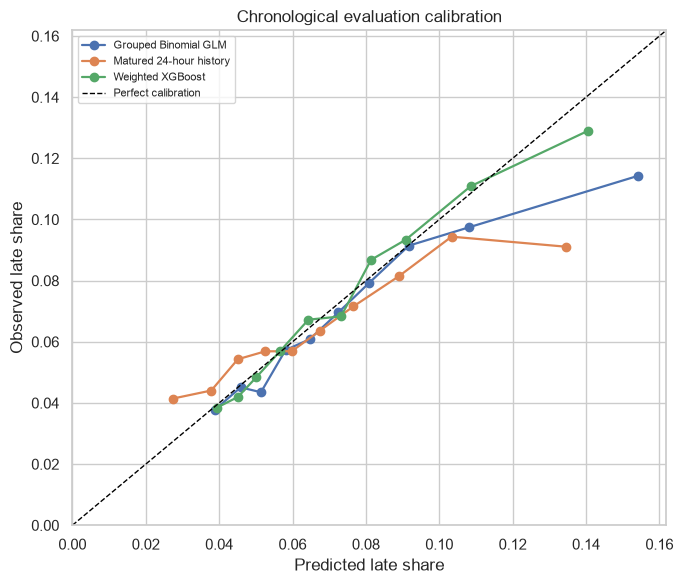

In [101]:
MODEL_DISPLAY_NAMES = {
    "Matured 24-hour history": "Matured 24-hour history",
    GLM_MODEL_NAME: GLM_MODEL_NAME,
    XGB_MODEL_NAME: XGB_MODEL_NAME,
}

figure, axis = plt.subplots(figsize=(7, 6))

# Plot observed against predicted risk within each calibration bin
for model_name, calibration_data in evaluation_calibration_df.groupby(
    "model_name"
):
    axis.plot(
        calibration_data["predicted_late_share"],
        calibration_data["observed_late_share"],
        marker="o",
        linewidth=1.6,
        label=MODEL_DISPLAY_NAMES[model_name],
    )

calibration_limit = 1.05 * max(
    evaluation_calibration_df[
        ["predicted_late_share", "observed_late_share"]
    ].max()
)
axis.plot(
    [0, calibration_limit],
    [0, calibration_limit],
    linestyle="--",
    color="black",
    linewidth=1,
    label="Perfect calibration",
)
axis.set_xlim(0, calibration_limit)
axis.set_ylim(0, calibration_limit)
axis.set_xlabel("Predicted late share")
axis.set_ylabel("Observed late share")
axis.set_title("Chronological evaluation calibration")
axis.legend(fontsize=8)
figure.tight_layout()
save_report_figure(figure, "wav_model_calibration")
plt.show()


## 9.3 Temporal, support, and weather robustness

Evaluate low-support sensitivity, HRRR forecast contribution, expanding monthly
performance, permutation importance, forecast-precipitation regimes, and GLM weather
associations without assigning causal meaning.


In [102]:
# Compare headline performance with and without Staten Island
low_support_metric_records = []

for scope_name, scope_mask in {
    "All five boroughs": pd.Series(True, index=evaluation_scoring_df.index),
    "Exclude Staten Island": evaluation_scoring_df["borough"].ne(
        "Staten Island"
    ),
}.items():
    low_support_metric_records.append(
        calculate_forecast_metrics(
            evaluation_scoring_df.loc[scope_mask],
            SELECTED_XGB_PREDICTION_COLUMN,
            SELECTED_XGB_MODEL_NAME,
            evaluation_group=scope_name,
        )
    )

low_support_summary_df = pd.DataFrame(low_support_metric_records)
low_support_summary_df[
    [
        "evaluation_group",
        "wav_request_count",
        "weighted_mae_percentage_points",
        "unweighted_mae_percentage_points",
    ]
]


,evaluation_group,wav_request_count,weighted_mae_percentage_points,unweighted_mae_percentage_points
0,All five boroughs,114672,2.5885,5.2526
1,Exclude Staten Island,112924,2.4708,3.7779


### HRRR forecast feature ablation

Compare weighted XGBoost with and without the six issue-time HRRR summaries.
The ablation uses its own validation-selected tree count and remains separate from
the formal model comparison and operational diagnostics.


In [103]:
xgb_without_hrrr_evaluation_scoring_df = (
    evaluation_outcomes_df
    .merge(
        xgb_without_hrrr_forecasts_df,
        on=list(MODEL_KEY_COLUMNS),
        how="left",
    )
)
hrrr_feature_ablation_records = []
for (
    evaluation_period,
    scoring_data,
    prediction_column,
    feature_set,
    tree_count,
) in (
    (
        "Validation",
        xgb_validation_scoring_df,
        XGB_VALIDATION_PREDICTION_COLUMN,
        "With HRRR forecasts",
        XGB_TREE_COUNT,
    ),
    (
        "Validation",
        xgb_without_hrrr_validation_scoring_df,
        XGB_WITHOUT_HRRR_VALIDATION_PREDICTION_COLUMN,
        "Without HRRR forecasts",
        XGB_WITHOUT_HRRR_TREE_COUNT,
    ),
    (
        "Chronological evaluation",
        evaluation_scoring_df,
        XGB_PREDICTION_COLUMN,
        "With HRRR forecasts",
        XGB_TREE_COUNT,
    ),
    (
        "Chronological evaluation",
        xgb_without_hrrr_evaluation_scoring_df,
        XGB_WITHOUT_HRRR_PREDICTION_COLUMN,
        "Without HRRR forecasts",
        XGB_WITHOUT_HRRR_TREE_COUNT,
    ),
):
    metric_record = calculate_forecast_metrics(
        scoring_data,
        prediction_column,
        XGB_MODEL_NAME,
    )
    metric_record.update(
        {
            "evaluation_period": evaluation_period,
            "feature_set": feature_set,
            "selected_tree_count": tree_count,
        }
    )
    hrrr_feature_ablation_records.append(metric_record)

hrrr_feature_ablation_df = pd.DataFrame(
    hrrr_feature_ablation_records
).loc[
    :,
    [
        "evaluation_period",
        "feature_set",
        "weighted_mae_percentage_points",
        "weighted_rmse_percentage_points",
        "selected_tree_count",
    ],
]
hrrr_feature_ablation_df.to_csv(
    TABLE_OUTPUT_ROOT / "wav_hrrr_feature_ablation.csv",
    index=False,
)
hrrr_feature_ablation_df


,evaluation_period,feature_set,weighted_mae_percentage_points,weighted_rmse_percentage_points,selected_tree_count
0,Validation,With HRRR forecasts,2.5496,3.7250,125
1,Validation,Without HRRR forecasts,2.5075,3.6599,142
2,Chronological evaluation,With HRRR forecasts,2.5885,3.7164,125
3,Chronological evaluation,Without HRRR forecasts,2.6636,3.7266,142


In [104]:
# Freeze development-period monthly robustness folds
EXPANDING_BACKTEST_FOLDS = (
    (
        "July 2025",
        pd.Timestamp("2025-07-01"),
        pd.Timestamp("2025-08-01"),
    ),
    (
        "August 2025",
        pd.Timestamp("2025-08-01"),
        pd.Timestamp("2025-09-01"),
    ),
    (
        "September 2025",
        pd.Timestamp("2025-09-01"),
        pd.Timestamp("2025-10-01"),
    ),
    (
        "October 2025",
        pd.Timestamp("2025-10-01"),
        pd.Timestamp("2025-11-01"),
    ),
)

In [105]:
backtest_metric_records = []
backtest_source_df = add_borough_time_block(
    model_panel_df.loc[
        model_panel_df["split_label"].isin(
            ["training", "validation"]
        )
        & model_panel_df["target_observed"]
    ].copy()
)

# Expand the training window while holding out one later month per fold
for fold_name, evaluation_start, evaluation_end in (
    EXPANDING_BACKTEST_FOLDS
):
    backtest_training_df = backtest_source_df.loc[
        backtest_source_df["period_start"] < evaluation_start
    ].copy()
    backtest_evaluation_df = backtest_source_df.loc[
        backtest_source_df["period_start"].between(
            evaluation_start,
            evaluation_end,
            inclusive="left",
        )
    ].copy()

    training_borough_risk = (
        backtest_training_df
        .groupby("borough")
        .apply(
            lambda data: (
                data["late_trip_count"].sum()
                / data["wav_request_count"].sum()
            ),
            include_groups=False,
        )
    )
    training_global_risk = (
        backtest_training_df["late_trip_count"].sum()
        / backtest_training_df["wav_request_count"].sum()
    )
    persistence_predictions = (
        backtest_evaluation_df["rolling_24h_late_share"]
        .fillna(
            backtest_evaluation_df["borough"].map(
                training_borough_risk
            )
        )
        .fillna(training_global_risk)
    )
    xgb_backtest_fit = fit_fixed_xgboost_model(
        fitting_data=backtest_training_df,
        prediction_data=backtest_evaluation_df,
        categorical_features=XGB_CATEGORICAL_FEATURES,
        numeric_features=MODEL_NUMERIC_FEATURES,
        configuration=XGB_REGULARISED_CONFIGURATION,
        tree_count=XGB_TREE_COUNT,
    )

    fold_scoring_df = backtest_evaluation_df[
        [*MODEL_KEY_COLUMNS, *MODEL_TARGET_COLUMNS]
    ].copy()
    fold_scoring_df["backtest_persistence_prediction"] = (
        persistence_predictions.to_numpy()
    )
    fold_scoring_df["backtest_xgb_prediction"] = (
        xgb_backtest_fit["predictions"]
    )

    for model_name, prediction_column in {
        "Matured 24-hour history": (
            "backtest_persistence_prediction"
        ),
        XGB_MODEL_NAME: (
            "backtest_xgb_prediction"
        ),
    }.items():
        metric_record = calculate_forecast_metrics(
            fold_scoring_df,
            prediction_column,
            model_name,
            evaluation_group=fold_name,
        )
        metric_record.update(
            {
                "fold_name": fold_name,
                "training_end_exclusive": evaluation_start,
                "evaluation_end_exclusive": evaluation_end,
                "training_row_count": len(backtest_training_df),
            }
        )
        backtest_metric_records.append(metric_record)

expanding_backtest_metrics_df = pd.DataFrame(
    backtest_metric_records
)
expanding_backtest_metrics_df.to_csv(
    TABLE_OUTPUT_ROOT / "wav_expanding_backtest_metrics.csv",
    index=False,
)
expanding_backtest_metrics_df.pivot(
    index="fold_name",
    columns="model_name",
    values="weighted_mae_percentage_points",
)


model_name,Matured 24-hour history,Weighted XGBoost
fold_name,,
August 2025,3.5286,4.5231
July 2025,4.2403,4.5389
October 2025,2.7702,2.3685
September 2025,3.1718,2.7742


In [106]:
XGB_PREDICTOR_COLUMNS = (
    *XGB_CATEGORICAL_FEATURES,
    *MODEL_NUMERIC_FEATURES,
)
xgb_validation_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            xgb_validation_fit["preprocessor"],
        ),
        (
            "model",
            xgb_validation_fit["model"],
        ),
    ]
)
xgb_permutation_result = permutation_importance(
    xgb_validation_pipeline,
    model_validation_df.loc[:, XGB_PREDICTOR_COLUMNS],
    model_validation_df["late_share"],
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    n_jobs=1,
    random_state=RANDOM_SEED,
    sample_weight=model_validation_df["wav_request_count"],
)
xgb_permutation_importance_df = (
    pd.DataFrame(
        {
            "feature_name": XGB_PREDICTOR_COLUMNS,
            "importance_mean": (
                xgb_permutation_result.importances_mean
            ),
            "importance_standard_deviation": (
                xgb_permutation_result.importances_std
            ),
        }
    )
    .assign(
        importance_mean_percentage_points=lambda data: (
            100 * data["importance_mean"]
        ),
        importance_standard_deviation_percentage_points=(
            lambda data: (
                100 * data["importance_standard_deviation"]
            )
        ),
    )
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)
xgb_permutation_importance_df.to_csv(
    MODEL_OUTPUT_ROOT / "wav_xgboost_importance.csv",
    index=False,
)


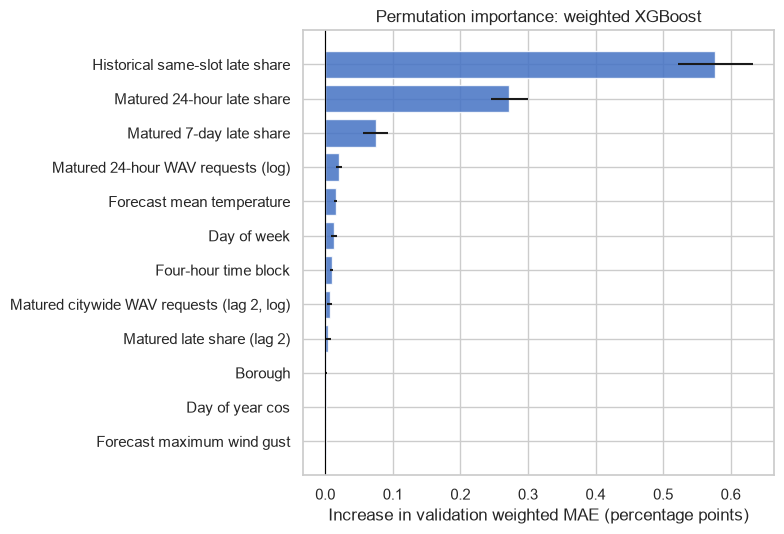

In [107]:
PERMUTATION_FEATURE_DISPLAY_NAMES = {
    "historical_same_slot_late_share": (
        "Historical same-slot late share"
    ),
    "rolling_24h_late_share": "Matured 24-hour late share",
    "rolling_7d_late_share": "Matured 7-day late share",
    "log1p_lag_2_citywide_wav_request_count": (
        "Matured citywide WAV requests (lag 2, log)"
    ),
    "log1p_rolling_24h_wav_request_count": (
        "Matured 24-hour WAV requests (log)"
    ),
    "log1p_lag_2_wav_request_count": (
        "Matured WAV requests (lag 2, log)"
    ),
    "lag_2_late_share": "Matured late share (lag 2)",
    "hrrr_forecast_mean_temperature_c": (
        "Forecast mean temperature"
    ),
    "hrrr_forecast_mean_relative_humidity_pct": (
        "Forecast mean relative humidity"
    ),
    "hrrr_forecast_total_precipitation_mm": (
        "Forecast total precipitation"
    ),
    "hrrr_forecast_any_rain": "Forecast any rain",
    "hrrr_forecast_mean_wind_speed_ms": (
        "Forecast mean wind speed"
    ),
    "hrrr_forecast_max_wind_gust_ms": (
        "Forecast maximum wind gust"
    ),
    "time_block": "Four-hour time block",
    "day_of_week": "Day of week",
    "borough": "Borough",
    "days_since_analysis_start": "Days since analysis start",
}

importance_plot_data = (
    xgb_permutation_importance_df.head(12)
    .sort_values("importance_mean_percentage_points")
)
importance_plot_data["feature_display_name"] = (
    importance_plot_data["feature_name"]
    .map(PERMUTATION_FEATURE_DISPLAY_NAMES)
    .fillna(
        importance_plot_data["feature_name"]
        .str.replace("_", " ", regex=False)
        .str.capitalize()
    )
)

figure, axis = plt.subplots(figsize=(8, 5.5))
axis.barh(
    importance_plot_data["feature_display_name"],
    importance_plot_data["importance_mean_percentage_points"],
    xerr=importance_plot_data[
        "importance_standard_deviation_percentage_points"
    ],
    color="#4472C4",
    alpha=0.85,
)
axis.axvline(0, color="black", linewidth=0.8)
axis.set_xlabel(
    "Increase in validation weighted MAE (percentage points)"
)
axis.set_ylabel("")
axis.set_title("Permutation importance: weighted XGBoost")
figure.tight_layout()
save_report_figure(figure, "wav_permutation_importance")
plt.show()


In [108]:
# Diagnose validation performance across forecast-precipitation regimes
validation_diagnostic_df = model_validation_df[
    [
        *MODEL_KEY_COLUMNS,
        *MODEL_TARGET_COLUMNS,
        "hrrr_forecast_total_precipitation_mm",
    ]
].copy()
validation_diagnostic_df[GLM_VALIDATION_PREDICTION_COLUMN] = (
    glm_validation_fit["predictions"]
)
validation_diagnostic_df[XGB_VALIDATION_PREDICTION_COLUMN] = (
    xgb_validation_fit["predictions"]
)
forecast_precipitation = validation_diagnostic_df[
    "hrrr_forecast_total_precipitation_mm"
]
validation_diagnostic_df["forecast_weather_regime"] = (
    np.select(
        [
            forecast_precipitation.eq(0),
            forecast_precipitation.le(1),
        ],
        ["Dry forecast", "Up to 1 mm forecast"],
        default="More than 1 mm forecast",
    )
)

weather_regime_metric_records = []
for weather_regime, regime_data in (
    validation_diagnostic_df.groupby(
        "forecast_weather_regime",
        observed=True,
    )
):
    for model_name, prediction_column in {
        GLM_MODEL_NAME: GLM_VALIDATION_PREDICTION_COLUMN,
        XGB_MODEL_NAME: XGB_VALIDATION_PREDICTION_COLUMN,
    }.items():
        metric_record = calculate_forecast_metrics(
            regime_data,
            prediction_column,
            model_name,
            evaluation_group=str(weather_regime),
        )
        metric_record["observed_late_share_percentage"] = (
            100 * metric_record["observed_weighted_late_share"]
        )
        weather_regime_metric_records.append(metric_record)

weather_regime_metrics_df = pd.DataFrame(
    weather_regime_metric_records
)
weather_regime_metrics_df[
    [
        "model_name",
        "evaluation_group",
        "row_count",
        "wav_request_count",
        "observed_late_share_percentage",
        "weighted_mae_percentage_points",
    ]
]


,model_name,evaluation_group,row_count,wav_request_count,observed_late_share_percentage,weighted_mae_percentage_points
0,Grouped Binomial GLM,Dry forecast,1430,102635,6.5231,2.5348
1,Weighted XGBoost,Dry forecast,1430,102635,6.5231,2.4752
2,Grouped Binomial GLM,More than 1 mm forecast,103,5528,6.3857,3.7990
3,Weighted XGBoost,More than 1 mm forecast,103,5528,6.3857,3.5581
4,Grouped Binomial GLM,Up to 1 mm forecast,201,12253,6.5698,2.6686
5,Weighted XGBoost,Up to 1 mm forecast,201,12253,6.5698,2.7175


In [109]:
# Summarise standardised HRRR associations from the grouped-binomial GLM
glm_weather_confidence_intervals = final_glm_result.conf_int()
glm_weather_associations_df = pd.DataFrame(
    {
        "feature_name": HRRR_FORECAST_MODEL_FEATURES,
        "standardised_log_odds_coefficient": [
            final_glm_result.params[feature_name]
            for feature_name in HRRR_FORECAST_MODEL_FEATURES
        ],
        "confidence_interval_lower": [
            glm_weather_confidence_intervals.loc[feature_name, 0]
            for feature_name in HRRR_FORECAST_MODEL_FEATURES
        ],
        "confidence_interval_upper": [
            glm_weather_confidence_intervals.loc[feature_name, 1]
            for feature_name in HRRR_FORECAST_MODEL_FEATURES
        ],
        "p_value": [
            final_glm_result.pvalues[feature_name]
            for feature_name in HRRR_FORECAST_MODEL_FEATURES
        ],
    }
)
glm_weather_associations_df[
    "odds_ratio_per_training_standard_deviation"
] = np.exp(
    glm_weather_associations_df[
        "standardised_log_odds_coefficient"
    ]
)
glm_weather_associations_df


,feature_name,standardised_log_odds_coefficient,confidence_interval_lower,confidence_interval_upper,p_value,odds_ratio_per_training_standard_deviation
0,hrrr_forecast_mean_temperature_c,0.1398,0.0627,0.2168,0.0004,1.1500
1,hrrr_forecast_mean_relative_humidity_pct,0.0217,-0.0168,0.0602,0.2697,1.0219
2,hrrr_forecast_total_precipitation_mm,0.0537,0.0367,0.0707,0.0000,1.0552
3,hrrr_forecast_any_rain,0.0182,-0.0104,0.0468,0.2118,1.0184
4,hrrr_forecast_mean_wind_speed_ms,-0.0076,-0.0794,0.0643,0.8361,0.9924
5,hrrr_forecast_max_wind_gust_ms,0.0084,-0.0714,0.0883,0.8357,1.0085
